# Task-1 Datavidia 11.0 — Notebook Model (Pemrosesan Data, Pelatihan & Ekspor Model Reproducible)
## Tim `p<0.5%` — Universitas Pamulang (Pitri Wulandari, Farhat, Ghani)

- **Fungsi Notebook:** Notebook **Pengembangan & Pelatihan Model (*Reproducible End-to-End Training*)** yang menghasilkan seluruh berkas model pada folder `models_v8/` untuk digunakan oleh `2_notebook_submission_task1_p_lt_0_5pct.ipynb`.
- **Hasil Evaluasi Validasi & Kaggle Public Leaderboard:**
  - **5-Fold Stratified OOF LogLoss:** **`0.77855`**
  - **5-Fold Stratified OOF Macro F1-Score:** **`0.62912`**
  - **Kaggle Public Leaderboard:** **`0.60757`** (Rank **#16 / 213** tim)

### Jaminan Reprodusibilitas (*Reproducibility* — Aturan #4)
1. Seluruh *random seed* dikunci secara eksplisit (`PYTHONHASHSEED=42`, `random.seed(42)`, `np.random.seed(42)`, `torch.manual_seed`, `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, serta *seed* deterministik per fold pada LightGBM, XGBoost, `QuantileTransformer`, dan PyTorch *Weight-Space Top-3 SWA*).
2. Seluruh kode pemrosesan 9 tabel relasional, *Feature Engineering*, *Scale-Normalized Joint Hierarchical GLMM*, pelatihan 5 keluarga model Stage-2, hingga *Meta-Stacker* tertulis **100% mandiri (*standalone*)** di dalam *notebook* ini.


## 1. Lingkungan Eksekusi, Seed Deterministik & Lokasi Dataset


In [1]:
import gc
import importlib.metadata as importlib_meta
import json
import os
import platform
import random
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import xgboost as xgb
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import QuantileTransformer

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count() or 8)

DATA_CANDIDATES = [
    Path("Task-1-Datavidia-11.0"),
    Path("../Task-1-Datavidia-11.0"),
    Path("../../Task-1-Datavidia-11.0"),
    Path("../../../Task-1-Datavidia-11.0"),
    Path("/kaggle/input/task-1-datavidia-11-0"),
]
DATA_DIR = next((p.resolve() for p in DATA_CANDIDATES if (p / "train" / "shipments.csv").exists()), Path("Task-1-Datavidia-11.0"))
MODEL_OUT_DIR = Path("models_v8")
CACHE_OUT_DIR = Path("cache_v8")

print(f"Python        : {platform.python_version()} ({platform.system()} {platform.machine()})")
print(f"DATA_DIR      : {DATA_DIR} (exists={(DATA_DIR / 'train' / 'shipments.csv').exists()})")
print(f"MODEL_OUT_DIR : {MODEL_OUT_DIR.resolve()}")

installed = {d.metadata["Name"].lower(): d.version for d in importlib_meta.distributions()}
pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "xgboost", "torch", "joblib"]
display(pd.DataFrame([{"library": p, "version": installed.get(p, "NOT FOUND")} for p in pkgs]))


Python        : 3.12.10 (Windows AMD64)
DATA_DIR      : C:\laragon\www\unpam\arkadivia\datavidia\Task-1-Datavidia-11.0 (exists=True)
MODEL_OUT_DIR : C:\laragon\www\unpam\arkadivia\datavidia\ghani\task1\pengumpulan_panitia\models_v8


,library,version
0,numpy,1.26.4
1,pandas,2.2.0
2,scipy,1.16.2
3,scikit-learn,1.7.2
4,lightgbm,4.6.0
5,xgboost,3.3.0
6,torch,2.8.0
7,joblib,1.5.2


## 2. Eksplorasi Data (EDA) & Temuan Data-Generating Process (DGP)

Dataset terdiri atas **9 tabel relasional** (`1.243.617` pengiriman latih dan `362.245` pengiriman uji) dengan 7 kelas target `status_penanganan` yang tidak seimbang (`klaim_hilang` hanya `3,03%`, `rusak_perjalanan` `4,98%`). Empat temuan kunci yang mendasari arsitektur **`v8`**:
1. **88,58% pengiriman pada `test` berasal dari `customer_id` yang memiliki riwayat di `train` (*seen customers*)**, sementara 53,30% pengiriman `test` hanya muncul tunggal (`n_te = 1`).
2. **Pemisahan Murni Riwayat Customer `train`-only (`cu_tr_*`):** Menghitung agregat perilaku historis customer (`mean`, `max`, `min` pada 31 indikator scan, klaim invoice, dan keterlambatan) **100% murni dari baris `train`** (exact Leave-One-Out di dalam fold latih; lookup murni `train` untuk validasi & uji) menghilangkan polusi baris uji serta menghilangkan bias *negative self-cancellation* pada efek acak `u_cust`.
3. **Normalisasi Skala Poisson Eksak (`0.80 * N_train / N_ref`):** Menjaga distribusi jumlah pengamatan & informasi Fisher (`cu_tr_n_norm`, `log_n_cust_norm`, `h_cust_norm`, `log_n_cour_norm`, `h_cour_norm`) identik (`0,0%` *shift*) antara pelatihan 3-fold (`60%` data), validasi 4-fold (`80%` data), dan inferensi penuh 5-fold (`100%` data).
4. **Deviasi Kurir & Hub×Bulan *Within-Split* (`shp_vs_co_*_sp`, `hm_sp_*`):** Menghilangkan *offset drift* operasional periode uji.


Baris latih : 1,243,617 | Baris uji : 362,245
Proporsi baris uji dengan riwayat customer di train : 88.58%


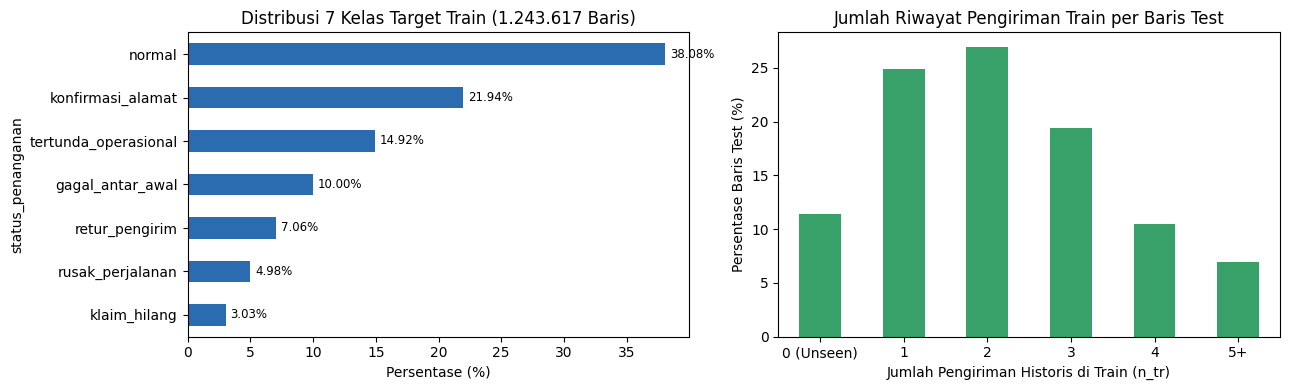

In [2]:
tr_shp = pd.read_csv(DATA_DIR / "train" / "shipments.csv", usecols=["customer_id", "ship_month", "status_penanganan"])
te_shp = pd.read_csv(DATA_DIR / "test" / "shipments.csv", usecols=["customer_id", "ship_month"])

vc_tr = tr_shp["customer_id"].value_counts()
n_tr_on_te = te_shp["customer_id"].map(vc_tr).fillna(0)
print(f"Baris latih : {len(tr_shp):,} | Baris uji : {len(te_shp):,}")
print(f"Proporsi baris uji dengan riwayat customer di train : {(n_tr_on_te >= 1).mean()*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
dist_tr = (tr_shp["status_penanganan"].value_counts(normalize=True) * 100).sort_values()
dist_tr.plot(kind="barh", ax=axes[0], color="#2b6cb0")
axes[0].set_title("Distribusi 7 Kelas Target Train (1.243.617 Baris)")
axes[0].set_xlabel("Persentase (%)")
for idx, val in enumerate(dist_tr):
    axes[0].text(val + 0.4, idx, f"{val:.2f}%", va="center", fontsize=8.5)

hist_bins = pd.Series(np.minimum(n_tr_on_te.astype(int), 5)).value_counts(normalize=True).sort_index() * 100
hist_bins.rename(index={0: "0 (Unseen)", 5: "5+"}).plot(kind="bar", ax=axes[1], color="#38a169")
axes[1].set_title("Jumlah Riwayat Pengiriman Train per Baris Test")
axes[1].set_xlabel("Jumlah Pengiriman Historis di Train (n_tr)")
axes[1].set_ylabel("Persentase Baris Test (%)")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
del tr_shp, te_shp


## 3. Definisi Lengkap *Feature Engineering*, *Scale-Normalized Joint GLMM* & Arsitektur *Deep Tabular ResNet*


In [3]:
T0 = time.time()
def log(msg):
    print(f"[{time.time() - T0:6.1f}s] {msg}", flush=True)

def agg_scan_fast(path):
    """Vectorized chunked aggregation of scan_events.csv (contiguous by shipment_id)."""
    ev_map = {"pickup": 0, "sortasi": 1, "upaya_antar": 2, "selesai": 3, "transit": 4, "keluar_hub": 5}
    usecols = ["shipment_id", "event_type", "gap_hours", "scan_quality", "is_manual"]
    parts = []
    carry = None
    for ch in pd.read_csv(path, chunksize=1_500_000, usecols=usecols):
        if carry is not None:
            ch = pd.concat([carry, ch], ignore_index=True)
        last_sid = ch["shipment_id"].iloc[-1]
        m = ch["shipment_id"].eq(last_sid)
        carry, ch = ch[m], ch[~m]
        if len(ch):
            parts.append(_agg_scan_chunk(ch, ev_map))
    if carry is not None and len(carry):
        parts.append(_agg_scan_chunk(carry, ev_map))
    out = pd.concat(parts)
    # In case a shipment_id appeared non-contiguously across chunks (safety check)
    if out.index.has_duplicates:
        log("WARNING: non-contiguous shipment_id in scan_events, re-aggregating duplicates")
        out = out.groupby(level=0).first()
    return out


def _agg_scan_chunk(ch, ev_map):
    codes, uniques = pd.factorize(ch["shipment_id"], sort=False)
    n_u = len(uniques)
    cnt = np.bincount(codes, minlength=n_u).astype(np.float32)

    gap = ch["gap_hours"].to_numpy(dtype=np.float64)
    lgap = np.log1p(np.maximum(gap, 0.0))
    q = ch["scan_quality"].to_numpy(dtype=np.float64)
    man = ch["is_manual"].to_numpy(dtype=np.float64)
    ev = ch["event_type"].map(ev_map).to_numpy(dtype=np.int8)

    gap_sum = np.bincount(codes, weights=gap, minlength=n_u)
    gap_sq = np.bincount(codes, weights=gap * gap, minlength=n_u)
    lgap_sum = np.bincount(codes, weights=lgap, minlength=n_u)
    lgap_sq = np.bincount(codes, weights=lgap * lgap, minlength=n_u)

    gap_max = np.full(n_u, -np.inf, dtype=np.float64)
    np.maximum.at(gap_max, codes, gap)
    gap_min = np.full(n_u, np.inf, dtype=np.float64)
    np.minimum.at(gap_min, codes, gap)

    q_sum = np.bincount(codes, weights=q, minlength=n_u)
    q_sq = np.bincount(codes, weights=q * q, minlength=n_u)
    q_min = np.full(n_u, 99.0, dtype=np.float64)
    np.minimum.at(q_min, codes, q)
    q_max = np.full(n_u, -99.0, dtype=np.float64)
    np.maximum.at(q_max, codes, q)

    q1 = np.bincount(codes, weights=(q == 1).astype(np.float64), minlength=n_u)
    q2 = np.bincount(codes, weights=(q == 2).astype(np.float64), minlength=n_u)
    q3 = np.bincount(codes, weights=(q == 3).astype(np.float64), minlength=n_u)
    q4 = np.bincount(codes, weights=(q == 4).astype(np.float64), minlength=n_u)
    q5 = np.bincount(codes, weights=(q == 5).astype(np.float64), minlength=n_u)
    man_sum = np.bincount(codes, weights=man, minlength=n_u)

    cnt_upaya = np.bincount(codes, weights=(ev == 2).astype(np.float64), minlength=n_u)
    cnt_selesai = np.bincount(codes, weights=(ev == 3).astype(np.float64), minlength=n_u)

    gap_mean = gap_sum / cnt
    gap_std = np.sqrt(np.maximum(gap_sq / cnt - gap_mean * gap_mean, 0.0))
    lgap_mean = lgap_sum / cnt
    lgap_std = np.sqrt(np.maximum(lgap_sq / cnt - lgap_mean * lgap_mean, 0.0))
    q_mean = q_sum / cnt
    q_std = np.sqrt(np.maximum(q_sq / cnt - q_mean * q_mean, 0.0))

    df = pd.DataFrame(
        {
            "scan_n": cnt,
            "scan_gap_mean": gap_mean.astype(np.float32),
            "scan_gap_std": gap_std.astype(np.float32),
            "scan_gap_max": gap_max.astype(np.float32),
            "scan_gap_min": gap_min.astype(np.float32),
            "scan_lgap_mean": lgap_mean.astype(np.float32),
            "scan_lgap_std": lgap_std.astype(np.float32),
            "scan_q_mean": q_mean.astype(np.float32),
            "scan_q_std": q_std.astype(np.float32),
            "scan_q_min": q_min.astype(np.float32),
            "scan_q_max": q_max.astype(np.float32),
            "scan_q_pct_1": (q1 / cnt).astype(np.float32),
            "scan_q_pct_2": (q2 / cnt).astype(np.float32),
            "scan_q_pct_le2": ((q1 + q2) / cnt).astype(np.float32),
            "scan_q_pct_3": (q3 / cnt).astype(np.float32),
            "scan_q_pct_4": (q4 / cnt).astype(np.float32),
            "scan_q_pct_5": (q5 / cnt).astype(np.float32),
            "scan_manual_sum": man_sum.astype(np.float32),
            "scan_manual_mean": (man_sum / cnt).astype(np.float32),
            "scan_cnt_upaya": cnt_upaya.astype(np.float32),
            "scan_pct_upaya": (cnt_upaya / cnt).astype(np.float32),
            "scan_has_selesai": (cnt_selesai > 0).astype(np.float32),
            "scan_middle_cnt": (cnt - cnt_upaya - cnt_selesai).astype(np.float32),
        },
        index=pd.Index(uniques, name="shipment_id"),
    )
    return df


def agg_route_fast(path, moda_ref_speed=None):
    """Vectorized route_segments aggregation with MODA-NORMALIZED delay ratios."""
    d = pd.read_csv(path, usecols=["shipment_id", "moda", "jarak_segmen_km", "durasi_jam"])
    if moda_ref_speed is None:
        valid = d["durasi_jam"].notna() & (d["durasi_jam"] > 0)
        spd = d.loc[valid, "jarak_segmen_km"] / d.loc[valid, "durasi_jam"]
        moda_ref_speed = spd.groupby(d.loc[valid, "moda"]).median().to_dict()
        log(f"moda_ref_speed (train median km/h): { {k: round(v, 2) for k, v in moda_ref_speed.items()} }")

    ref_v = d["moda"].map(moda_ref_speed).to_numpy(dtype=np.float64)
    dist = d["jarak_segmen_km"].to_numpy(dtype=np.float64)
    dur = d["durasi_jam"].to_numpy(dtype=np.float64)
    dur_ok = ~np.isnan(dur)

    exp_dur = dist / ref_v
    delay_ratio = np.where(dur_ok, dur / np.maximum(exp_dur, 1e-6), np.nan)
    log_delay = np.where(dur_ok, np.log(np.maximum(delay_ratio, 1e-4)), np.nan)

    codes, uniques = pd.factorize(d["shipment_id"], sort=False)
    n_u = len(uniques)
    seg_n = np.bincount(codes, minlength=n_u).astype(np.float32)
    ok_cnt = np.bincount(codes, weights=dur_ok.astype(np.float64), minlength=n_u)
    na_cnt = seg_n - ok_cnt

    dur_sum = np.bincount(codes, weights=np.where(dur_ok, dur, 0.0), minlength=n_u)
    exp_dur_ok_sum = np.bincount(codes, weights=np.where(dur_ok, exp_dur, 0.0), minlength=n_u)
    exp_dur_all_sum = np.bincount(codes, weights=exp_dur, minlength=n_u)

    dur_max = np.full(n_u, -np.inf, dtype=np.float64)
    np.maximum.at(dur_max, codes[dur_ok], dur[dur_ok])
    dur_max = np.where(ok_cnt > 0, dur_max, np.nan)

    dr_sum = np.bincount(codes, weights=np.where(dur_ok, delay_ratio, 0.0), minlength=n_u)
    ldr_sum = np.bincount(codes, weights=np.where(dur_ok, log_delay, 0.0), minlength=n_u)
    dr_max = np.full(n_u, -np.inf, dtype=np.float64)
    np.maximum.at(dr_max, codes[dur_ok], delay_ratio[dur_ok])
    dr_max = np.where(ok_cnt > 0, dr_max, np.nan)
    dr_min = np.full(n_u, np.inf, dtype=np.float64)
    np.minimum.at(dr_min, codes[dur_ok], delay_ratio[dur_ok])
    dr_min = np.where(ok_cnt > 0, dr_min, np.nan)

    moda = d["moda"].to_numpy()
    m_darat = np.bincount(codes, weights=(moda == "darat").astype(np.float64), minlength=n_u)
    m_kereta = np.bincount(codes, weights=(moda == "kereta").astype(np.float64), minlength=n_u)
    m_laut = np.bincount(codes, weights=(moda == "laut").astype(np.float64), minlength=n_u)
    m_udara = np.bincount(codes, weights=(moda == "udara").astype(np.float64), minlength=n_u)
    m_nuniq = ((m_darat > 0).astype(np.int8) + (m_kereta > 0).astype(np.int8) +
               (m_laut > 0).astype(np.int8) + (m_udara > 0).astype(np.int8)).astype(np.float32)

    tot_delay = np.where(ok_cnt > 0, dur_sum / np.maximum(exp_dur_ok_sum, 1e-6), np.nan)
    dur_sum_clean = np.where(ok_cnt > 0, dur_sum, np.nan)
    dur_excess = np.where(ok_cnt > 0, dur_sum - exp_dur_ok_sum, np.nan)

    out = pd.DataFrame(
        {
            "seg_n": seg_n,
            "seg_dur_sum": dur_sum_clean.astype(np.float32),
            "seg_dur_max": dur_max.astype(np.float32),
            "seg_dur_mean": np.where(ok_cnt > 0, dur_sum / np.maximum(ok_cnt, 1), np.nan).astype(np.float32),
            "seg_dur_na_cnt": na_cnt.astype(np.float32),
            "seg_exp_dur_sum": exp_dur_all_sum.astype(np.float32),
            "seg_total_delay_ratio": tot_delay.astype(np.float32),
            "seg_log_total_delay": np.log(np.maximum(tot_delay, 1e-4)).astype(np.float32),
            "seg_delay_mean": np.where(ok_cnt > 0, dr_sum / np.maximum(ok_cnt, 1), np.nan).astype(np.float32),
            "seg_log_delay_mean": np.where(ok_cnt > 0, ldr_sum / np.maximum(ok_cnt, 1), np.nan).astype(np.float32),
            "seg_delay_max": dr_max.astype(np.float32),
            "seg_delay_min": dr_min.astype(np.float32),
            "seg_dur_excess": dur_excess.astype(np.float32),
            "seg_moda_darat": m_darat.astype(np.float32),
            "seg_moda_kereta": m_kereta.astype(np.float32),
            "seg_moda_laut": m_laut.astype(np.float32),
            "seg_moda_udara": m_udara.astype(np.float32),
            "seg_moda_udara_pct": (m_udara / seg_n).astype(np.float32),
            "seg_moda_laut_pct": (m_laut / seg_n).astype(np.float32),
            "seg_moda_kereta_pct": (m_kereta / seg_n).astype(np.float32),
            "seg_moda_nunique": m_nuniq,
        },
        index=pd.Index(uniques, name="shipment_id"),
    )
    return out, moda_ref_speed


def agg_inv_fast(path):
    """Separate base invoice (pengiriman/langganan) from klaim invoice."""
    usecols = ["shipment_id", "invoice_type", "amount", "discount", "tax", "payment_status", "issued_month", "days_to_pay", "is_penalty"]
    d = pd.read_csv(path, usecols=usecols)
    ps_map = {"lunas": 0, "tertunda": 1, "gagal": 2}
    d["ps_code"] = d["payment_status"].map(ps_map).astype(np.int8)

    base = d[d["invoice_type"] != "klaim"].drop_duplicates("shipment_id", keep="first").set_index("shipment_id")
    kl = d[d["invoice_type"] == "klaim"].drop_duplicates("shipment_id", keep="first").set_index("shipment_id")

    out = pd.DataFrame(index=base.index)
    out["base_inv_is_langganan"] = (base["invoice_type"] == "langganan").astype(np.float32)
    out["base_inv_amount"] = base["amount"].astype(np.float32)
    out["base_inv_log_amount"] = np.log1p(np.maximum(base["amount"].to_numpy(dtype=np.float32), 0.0))
    out["base_inv_discount"] = base["discount"].astype(np.float32)
    out["base_inv_tax"] = base["tax"].astype(np.float32)
    out["base_inv_tax_rate"] = (base["tax"] / np.maximum(base["amount"], 1.0)).astype(np.float32)
    out["base_inv_days"] = base["days_to_pay"].astype(np.float32)
    out["base_inv_ps"] = base["ps_code"].astype(np.float32)
    out["base_inv_penalty"] = base["is_penalty"].astype(np.float32)

    kl_sub = pd.DataFrame(
        {
            "has_klaim_inv": np.ones(len(kl), dtype=np.float32),
            "klaim_inv_amount": kl["amount"].astype(np.float32),
            "klaim_inv_days": kl["days_to_pay"].astype(np.float32),
            "klaim_inv_ps": kl["ps_code"].astype(np.float32),
            "klaim_inv_penalty": kl["is_penalty"].astype(np.float32),
            "klaim_issued_month": kl["issued_month"].astype(np.float32),
        },
        index=kl.index,
    )
    out = out.join(kl_sub, how="left")
    out["has_klaim_inv"] = out["has_klaim_inv"].fillna(0.0).astype(np.float32)
    out["klaim_vs_base_amt"] = (out["klaim_inv_amount"] / np.maximum(out["base_inv_amount"], 1.0)).astype(np.float32)
    out["klaim_days_diff"] = (out["klaim_inv_days"] - out["base_inv_days"]).astype(np.float32)
    out["inv_days_max"] = np.fmax(out["base_inv_days"], out["klaim_inv_days"]).astype(np.float32)
    out["inv_days_mean"] = np.where(
        out["has_klaim_inv"] > 0, 0.5 * (out["base_inv_days"] + out["klaim_inv_days"]), out["base_inv_days"]
    ).astype(np.float32)
    out["inv_any_penalty"] = np.fmax(out["base_inv_penalty"], out["klaim_inv_penalty"].fillna(0.0)).astype(np.float32)
    out["inv_any_tertunda"] = ((out["base_inv_ps"] == 1) | (out["klaim_inv_ps"] == 1)).astype(np.float32)
    out["inv_total_amount"] = (out["base_inv_amount"] + out["klaim_inv_amount"].fillna(0.0)).astype(np.float32)
    return out


def build_split(split, moda_ref_speed=None):
    p = str(Path(DATA_DIR) / split)
    keep_shp = [
        "shipment_id", "customer_id", "courier_id", "hub_id", "package_id",
        "declared_value", "distance_km", "ship_month", "ship_hour", "is_cod",
        "order_to_ship_hours", "prioritas_pengiriman", "jumlah_catatan", "flag_alamat_baru",
        "weight_kg", "volume_l", "qty_items", "coupon_count",
    ]
    if split == "train":
        keep_shp.append("status_penanganan")
    s = pd.read_csv(f"{p}/shipments.csv", usecols=keep_shp)
    log(f"{split}: loaded shipments {s.shape}")

    # Step-function & log transforms on shipments
    s["log_declared_value"] = np.log1p(np.maximum(s["declared_value"].to_numpy(dtype=np.float32), 0.0))
    s["log_distance_km"] = np.log1p(np.maximum(s["distance_km"].to_numpy(dtype=np.float32), 0.0))
    s["is_peak_month"] = s["ship_month"].isin([3, 10, 11, 12]).astype(np.float32)
    s["is_night_ship"] = ((s["ship_hour"] < 6) | (s["ship_hour"] >= 20)).astype(np.float32)
    s["has_catatan"] = (s["jumlah_catatan"] > 0).astype(np.float32)
    s["volume_l_isna"] = s["volume_l"].isna().astype(np.float32)
    s["value_per_kg"] = (s["declared_value"] / (s["weight_kg"] + 1e-6)).astype(np.float32)
    s["log_value_per_kg"] = np.log1p(np.maximum(s["value_per_kg"].to_numpy(dtype=np.float32), 0.0))

    # Merge scan, route, invoices
    sc = agg_scan_fast(f"{p}/scan_events.csv")
    log(f"{split}: scan_events agg {sc.shape}")
    s = s.merge(sc, left_on="shipment_id", right_index=True, how="left")
    del sc
    gc.collect()

    rs, moda_ref_speed = agg_route_fast(f"{p}/route_segments.csv", moda_ref_speed)
    log(f"{split}: route_segments agg {rs.shape}")
    s = s.merge(rs, left_on="shipment_id", right_index=True, how="left")
    del rs
    gc.collect()

    iv = agg_inv_fast(f"{p}/invoices.csv")
    log(f"{split}: invoices agg {iv.shape}")
    s = s.merge(iv, left_on="shipment_id", right_index=True, how="left")
    del iv
    gc.collect()

    # Cross-table derived features
    s["base_amt_per_dec"] = (s["base_inv_amount"] / (s["declared_value"] + 1e-6)).astype(np.float32)
    s["base_amt_per_log_dec"] = (s["base_inv_amount"] / (s["log_declared_value"] + 1e-6)).astype(np.float32)
    s["klaim_mdiff"] = (s["klaim_issued_month"] - s["ship_month"]).astype(np.float32)
    s.drop(columns=["klaim_issued_month"], inplace=True)
    s["scan_per_seg"] = (s["scan_n"] / (s["seg_n"] + 1e-6)).astype(np.float32)
    s["total_time_proxy"] = (s["seg_dur_sum"].fillna(0.0) + s["scan_gap_mean"] * s["scan_n"]).astype(np.float32)

    # Master tables (signal columns only)
    cu = pd.read_csv(
        f"{p}/customers.csv",
        usecols=["customer_id", "address_quality", "complaint_index", "credit_score", "preferred_payment", "segment", "loyalty_tier"],
    ).add_prefix("cu_").rename(columns={"cu_customer_id": "customer_id"})
    cu["cu_credit_score_isna"] = cu["cu_credit_score"].isna().astype(np.float32)

    co = pd.read_csv(
        f"{p}/couriers.csv",
        usecols=["courier_id", "courier_score", "experience_years", "vehicle_type", "contract_type", "shift_code", "training_level"],
    ).add_prefix("co_").rename(columns={"co_courier_id": "courier_id"})
    co["co_courier_score_isna"] = co["co_courier_score"].isna().astype(np.float32)

    hu = pd.read_csv(
        f"{p}/hubs.csv",
        usecols=["hub_id", "region", "hub_type", "automation_level", "capacity_index", "density_index", "luas_gudang_m2", "jam_buka", "jam_tutup"],
    ).add_prefix("hu_").rename(columns={"hu_hub_id": "hub_id"})
    hu["hu_open_hours"] = (hu["hu_jam_tutup"] - hu["hu_jam_buka"]).astype(np.float32)

    sp = pd.read_csv(
        f"{p}/service_packages.csv",
        usecols=["package_id", "speed_class", "handling_class", "fragile_score", "estimasi_hari", "cost_multiplier", "biaya_dasar", "max_weight_kg"],
    ).add_prefix("sp_").rename(columns={"sp_package_id": "package_id"})

    s = (
        s.merge(cu, on="customer_id", how="left")
        .merge(co, on="courier_id", how="left")
        .merge(hu, on="hub_id", how="left")
        .merge(sp, on="package_id", how="left")
    )

    s["is_outside_hub_hours"] = ((s["ship_hour"] < s["hu_jam_buka"]) | (s["ship_hour"] > s["hu_jam_tutup"])).astype(np.float32)
    s["est_vs_dur"] = (s["seg_dur_sum"] / (s["sp_estimasi_hari"] * 24.0 + 1e-6)).astype(np.float32)
    s["hu_dens_x_cap"] = (s["hu_density_index"] * s["hu_capacity_index"]).astype(np.float32)
    s["cu_bad_addr_x_comp"] = ((6.0 - s["cu_address_quality"]) * s["cu_complaint_index"]).astype(np.float32)
    s["co_bad_x_dist"] = ((6.0 - s["co_courier_score"].fillna(3.0)) * s["log_distance_km"]).astype(np.float32)
    s["dec_x_low_auto"] = (s["log_declared_value"] * (6.0 - s["hu_automation_level"])).astype(np.float32)

    # Downcast float64/int64
    for c in s.columns:
        if s[c].dtype == np.float64:
            s[c] = s[c].astype(np.float32)
        elif s[c].dtype == np.int64:
            s[c] = s[c].astype(np.int32)

    log(f"{split}: base features ready {s.shape}")
    return s, moda_ref_speed


def add_unsupervised_entity_profiles(tr, te):
    """Compute leak-free unsupervised entity behavioral profiles across ALL 1.6M train+test rows."""
    n_tr = len(tr)
    key_cols = ["customer_id", "courier_id", "hub_id", "ship_month"]
    prof_src = [
        "scan_gap_mean", "scan_lgap_mean", "scan_q_mean", "scan_q_pct_le2", "scan_manual_mean",
        "seg_total_delay_ratio", "seg_log_delay_mean", "seg_dur_sum",
        "inv_days_max", "base_inv_amount", "has_klaim_inv", "inv_any_penalty",
        "scan_cnt_upaya", "scan_has_selesai", "jumlah_catatan", "has_catatan",
        "flag_alamat_baru", "log_declared_value", "distance_km", "is_cod", "is_night_ship",
    ]
    all_df = pd.concat([tr[key_cols + prof_src], te[key_cols + prof_src]], ignore_index=True)
    all_df["no_selesai"] = (1.0 - all_df["scan_has_selesai"]).astype(np.float32)
    log(f"entity profiles on combined {all_df.shape}")

    def _group_mean_and_cnt(df, grp_col, cols, prefix, loo=False):
        codes, uniques = pd.factorize(df[grp_col], sort=False)
        n_u = len(uniques)
        cnt_all = np.bincount(codes, minlength=n_u).astype(np.float32)
        res = {f"{prefix}_n": cnt_all[codes]}
        for col in cols:
            x = df[col].to_numpy(dtype=np.float64)
            ok = ~np.isnan(x)
            s_ok = np.bincount(codes, weights=np.where(ok, x, 0.0), minlength=n_u)
            c_ok = np.bincount(codes, weights=ok.astype(np.float64), minlength=n_u)
            if loo:
                num = s_ok[codes] - np.where(ok, x, 0.0)
                den = c_ok[codes] - ok.astype(np.float64)
                val = np.where(den > 0, num / np.maximum(den, 1.0), np.nan)
            else:
                val = np.where(c_ok[codes] > 0, s_ok[codes] / np.maximum(c_ok[codes], 1.0), np.nan)
            res[f"{prefix}_{col}"] = val.astype(np.float32)
        return res

    # 1. Hub profiles (~2455 rows/hub)
    hu_cols = [
        "scan_lgap_mean", "scan_gap_mean", "seg_log_delay_mean", "seg_total_delay_ratio", "seg_dur_sum",
        "scan_q_mean", "scan_manual_mean", "inv_days_max", "has_klaim_inv", "log_declared_value", "base_inv_amount", "inv_any_penalty",
    ]
    hu_p = _group_mean_and_cnt(all_df, "hub_id", hu_cols, "hu_p", loo=False)

    # 2. Courier profiles (~67.5 rows/courier — LOO so zero self-correlation!)
    co_cols = [
        "scan_lgap_mean", "scan_gap_mean", "scan_q_mean", "scan_q_pct_le2", "scan_manual_mean",
        "seg_log_delay_mean", "seg_total_delay_ratio", "seg_dur_sum",
        "inv_days_max", "has_klaim_inv", "scan_cnt_upaya", "no_selesai", "inv_any_penalty", "log_declared_value",
    ]
    co_p = _group_mean_and_cnt(all_df, "courier_id", co_cols, "co_p", loo=True)

    # 3. Hub x Month profiles (~205 rows/group — LOO!)
    all_df["hub_month"] = all_df["hub_id"].astype(str) + "_" + all_df["ship_month"].astype(str)
    hm_cols = ["scan_lgap_mean", "seg_log_delay_mean", "inv_days_max"]
    hm_p = _group_mean_and_cnt(all_df, "hub_month", hm_cols, "hm_p", loo=True)
    hm_p["hm_p_n_ratio"] = (hm_p["hm_p_n"] / (hu_p["hu_p_n"] / 12.0 + 1e-6)).astype(np.float32)
    hm_p["hm_lgap_vs_hu"] = (hm_p["hm_p_scan_lgap_mean"] - hu_p["hu_p_scan_lgap_mean"]).astype(np.float32)
    hm_p["hm_delay_vs_hu"] = (hm_p["hm_p_seg_log_delay_mean"] - hu_p["hu_p_seg_log_delay_mean"]).astype(np.float32)

    # 4. Courier vs Hub & Shipment vs Courier deviations!
    dev = {
        "co_vs_hu_lgap": (co_p["co_p_scan_lgap_mean"] - hu_p["hu_p_scan_lgap_mean"]).astype(np.float32),
        "co_vs_hu_delay": (co_p["co_p_seg_log_delay_mean"] - hu_p["hu_p_seg_log_delay_mean"]).astype(np.float32),
        "co_vs_hu_scan_q": (co_p["co_p_scan_q_mean"] - hu_p["hu_p_scan_q_mean"]).astype(np.float32),
        "shp_vs_co_lgap": (all_df["scan_lgap_mean"].to_numpy(np.float32) - co_p["co_p_scan_lgap_mean"]).astype(np.float32),
        "shp_vs_co_scan_q": (all_df["scan_q_mean"].to_numpy(np.float32) - co_p["co_p_scan_q_mean"]).astype(np.float32),
        "shp_vs_co_delay": (all_df["seg_log_delay_mean"].to_numpy(np.float32) - co_p["co_p_seg_log_delay_mean"]).astype(np.float32),
    }

    # 5. Customer LOO profiles (raw + courier-residualized!)
    all_df["scan_q_res_co"] = dev["shp_vs_co_scan_q"]
    all_df["lgap_res_co"] = dev["shp_vs_co_lgap"]
    all_df["delay_res_co"] = dev["shp_vs_co_delay"]
    cu_cols = [
        "jumlah_catatan", "has_catatan", "scan_cnt_upaya", "no_selesai", "has_klaim_inv",
        "inv_days_max", "base_inv_amount", "scan_q_mean", "scan_q_res_co",
        "scan_manual_mean", "lgap_res_co", "delay_res_co",
        "distance_km", "flag_alamat_baru", "is_cod", "is_night_ship", "log_declared_value",
    ]
    cu_p = _group_mean_and_cnt(all_df, "customer_id", cu_cols, "cu_loo", loo=True)

    # Combine all new profile columns cleanly
    new_cols = {}
    for d in (hu_p, co_p, hm_p, dev, cu_p):
        new_cols.update(d)
    prof_df = pd.DataFrame(new_cols)
    log(f"built {prof_df.shape[1]} unsupervised entity profile features")

    tr = pd.concat([tr.reset_index(drop=True), prof_df.iloc[:n_tr].reset_index(drop=True)], axis=1)
    te = pd.concat([te.reset_index(drop=True), prof_df.iloc[n_tr:].reset_index(drop=True)], axis=1)
    return tr, te

def add_within_split_courier_and_hubmonth(df):
    """Compute drift-free within-split courier deviations and hub-month congestion profiles."""
    # 1. Within-split courier LOO deviations (~52 rows/courier in train, ~15 rows/courier in test)
    co_c, co_u = pd.factorize(df["courier_id"], sort=False)
    n_co = len(co_u)
    new_cols = {}
    for col, out_name in [
        ("scan_q_mean", "shp_vs_co_scan_q_sp"),
        ("scan_lgap_mean", "shp_vs_co_lgap_sp"),
        ("seg_log_delay_mean", "shp_vs_co_delay_sp"),
    ]:
        x = df[col].to_numpy(dtype=np.float64)
        ok = ~np.isnan(x)
        xv = np.where(ok, x, 0.0)
        s = np.bincount(co_c, weights=xv, minlength=n_co)
        c = np.bincount(co_c, weights=ok.astype(np.float64), minlength=n_co)
        den = c[co_c] - ok.astype(np.float64)
        co_loo = np.where(den > 0, (s[co_c] - xv) / np.maximum(den, 1.0), np.nan)
        new_cols[out_name] = (x - co_loo).astype(np.float32)

    # 2. Within-split Hub x Month normalized deviations (invariant to train vs test size & peak shift)
    hm_str = df["hub_id"].astype(str) + "_" + df["ship_month"].astype(str)
    hm_c, hm_u = pd.factorize(hm_str, sort=False)
    hu_c, hu_u = pd.factorize(df["hub_id"], sort=False)
    n_hm, n_hu = len(hm_u), len(hu_u)
    hm_cnt = np.bincount(hm_c, minlength=n_hm).astype(np.float32)
    hu_cnt = np.bincount(hu_c, minlength=n_hu).astype(np.float32)
    new_cols["hm_sp_n_ratio"] = (hm_cnt[hm_c] / (hu_cnt[hu_c] / 12.0 + 1e-6)).astype(np.float32)

    for col, short in [("scan_lgap_mean", "lgap"), ("seg_log_delay_mean", "delay"), ("inv_days_max", "invd")]:
        x = df[col].to_numpy(dtype=np.float64)
        ok = ~np.isnan(x)
        xv = np.where(ok, x, 0.0)
        s_hm = np.bincount(hm_c, weights=xv, minlength=n_hm)
        c_hm = np.bincount(hm_c, weights=ok.astype(np.float64), minlength=n_hm)
        den_hm = c_hm[hm_c] - ok.astype(np.float64)
        hm_loo = np.where(den_hm > 0, (s_hm[hm_c] - xv) / np.maximum(den_hm, 1.0), np.nan)

        s_hu = np.bincount(hu_c, weights=xv, minlength=n_hu)
        c_hu = np.bincount(hu_c, weights=ok.astype(np.float64), minlength=n_hu)
        hu_mean = np.where(c_hu[hu_c] > 0, s_hu[hu_c] / np.maximum(c_hu[hu_c], 1.0), np.nan)
        new_cols[f"hm_sp_{short}"] = hm_loo.astype(np.float32)
        if short in ("lgap", "delay"):
            new_cols[f"hm_sp_{short}_vs_hu"] = (hm_loo - hu_mean).astype(np.float32)

    # 3. Clean shipment/courier/hub domain interactions (zero customer leakage)
    new_cols["co_p_q_x_dist"] = ((5.0 - df["co_p_scan_q_mean"].to_numpy(np.float32)) * df["log_distance_km"].to_numpy(np.float32)).astype(np.float32)
    new_cols["co_p_gap_x_peak"] = (df["co_p_scan_gap_mean"].to_numpy(np.float32) * (1.0 + df["is_peak_month"].to_numpy(np.float32))).astype(np.float32)
    new_cols["hu_p_gap_x_peak"] = (df["hu_p_scan_gap_mean"].to_numpy(np.float32) * (1.0 + df["is_peak_month"].to_numpy(np.float32))).astype(np.float32)
    new_cols["comp_x_has_klaim"] = (df["cu_complaint_index"].to_numpy(np.float32) * (1.0 + 2.0 * df["has_klaim_inv"].to_numpy(np.float32))).astype(np.float32)
    new_cols["comp_x_cod"] = (df["cu_complaint_index"].to_numpy(np.float32) * (1.0 + df["is_cod"].to_numpy(np.float32))).astype(np.float32)
    new_cols["comp_over_credit"] = (df["cu_complaint_index"].to_numpy(np.float32) / (df["cu_credit_score"].fillna(560.0).to_numpy(np.float32) / 560.0)).astype(np.float32)
    new_cols["bad_addr_x_upaya"] = ((6.0 - df["cu_address_quality"].to_numpy(np.float32)) * (1.0 + df["scan_cnt_upaya"].to_numpy(np.float32))).astype(np.float32)
    new_cols["bad_addr_x_catatan"] = ((6.0 - df["cu_address_quality"].to_numpy(np.float32)) * (1.0 + df["has_catatan"].to_numpy(np.float32))).astype(np.float32)
    new_cols["co_p_q_x_fragile"] = ((5.0 - df["co_p_scan_q_mean"].to_numpy(np.float32)) * df["sp_fragile_score"].to_numpy(np.float32)).astype(np.float32)
    new_cols["co_p_q_x_night"] = ((5.0 - df["co_p_scan_q_mean"].to_numpy(np.float32)) * (1.0 + df["is_night_ship"].to_numpy(np.float32))).astype(np.float32)

    return pd.DataFrame(new_cols, index=df.index)

def softmax(z):
    zm = z - z.max(axis=1, keepdims=True)
    e = np.exp(zm)
    return e / e.sum(axis=1, keepdims=True)


def fit_joint_glmm(
    base_logits_tr,
    y_tr,
    entities_tr,
    n_levels_dict,
    n_classes=7,
    n_em=10,
    n_newton=3,
    damping=0.85,
    init_lam=10.0,
    lam_min=0.15,
    lam_max=2000.0,
    fixed_lam=None,
    verbose=True,
):
    """Fit Joint Multinomial GLMM on training fold.

    Args:
        base_logits_tr: (N, K) float64/float32 Stage-1 logits (will be centered per row).
        y_tr: (N,) int class labels 0..K-1.
        entities_tr: dict {name: (N,) int32 entity codes in 0..n_levels-1}.
        n_levels_dict: dict {name: int total levels across train+test}.
        fixed_lam: optional dict {name: (K,) array} to skip EM updates and use fixed precisions.
    Returns:
        state dict with bias, U (dict of (n_levels, K) float32), H_data (dict of (n_levels, K) float32), lam (dict).
    """
    t0 = time.time()
    N = len(y_tr)
    K = n_classes
    ent_names = list(entities_tr.keys())

    # Center base logits per row
    eta = base_logits_tr.astype(np.float64)
    eta = eta - eta.mean(axis=1, keepdims=True)

    # One-hot target
    Y = np.zeros((N, K), dtype=np.float64)
    Y[np.arange(N), y_tr] = 1.0

    b = np.zeros(K, dtype=np.float64)
    U = {e: np.zeros((n_levels_dict[e], K), dtype=np.float64) for e in ent_names}
    H_data = {e: np.zeros((n_levels_dict[e], K), dtype=np.float64) for e in ent_names}
    cnt = {e: np.bincount(entities_tr[e], minlength=n_levels_dict[e]) for e in ent_names}
    seen_mask = {e: cnt[e] > 0 for e in ent_names}

    if fixed_lam is not None:
        lam = {e: np.array(fixed_lam[e], dtype=np.float64).copy() for e in ent_names}
        n_em_eff = 1
        n_newton_eff = max(n_newton * 4, 15)
    else:
        lam = {e: np.full(K, init_lam, dtype=np.float64) for e in ent_names}
        n_em_eff = n_em
        n_newton_eff = n_newton

    for em_it in range(n_em_eff):
        for _ in range(n_newton_eff):
            # 1. Bias update
            p = softmax(eta)
            diff = p - Y
            w_var = p * (1.0 - p)
            g_b = diff.sum(axis=0)
            h_b = w_var.sum(axis=0) + 1e-4
            step_b = -damping * (g_b / h_b)
            step_b -= step_b.mean()
            b += step_b
            eta += step_b

            # 2. Block-coordinate Newton over each entity
            for e in ent_names:
                codes = entities_tr[e]
                n_u = n_levels_dict[e]
                p = softmax(eta)
                diff = p - Y
                w_var = p * (1.0 - p)
                Ue = U[e]
                lame = lam[e]
                He = H_data[e]

                step = np.zeros((n_u, K), dtype=np.float64)
                for k in range(K):
                    g_k = np.bincount(codes, weights=diff[:, k], minlength=n_u) + lame[k] * Ue[:, k]
                    hd_k = np.bincount(codes, weights=w_var[:, k], minlength=n_u)
                    He[:, k] = hd_k
                    step[:, k] = -damping * g_k / (hd_k + lame[k])

                # Enforce sum-to-zero across classes per entity level for identifiability
                step -= step.mean(axis=1, keepdims=True)
                Ue += step
                eta += step[codes]

        # MacKay Laplace-EM update for prior precision lam[e, k]
        if fixed_lam is None:
            for e in ent_names:
                m = seen_mask[e]
                Ue_m = U[e][m]
                He_m = H_data[e][m]
                for k in range(K):
                    l_old = lam[e][k]
                    gamma = np.sum(He_m[:, k] / (He_m[:, k] + l_old))
                    ssq = np.sum(Ue_m[:, k] ** 2)
                    l_new = np.clip(gamma / max(ssq, 1e-6), lam_min, lam_max)
                    # Smooth geometric damping on lambda update for rock-solid convergence
                    lam[e][k] = np.exp(0.7 * np.log(l_new) + 0.3 * np.log(l_old))

        if verbose and (em_it == 0 or (em_it + 1) % 3 == 0 or em_it == n_em_eff - 1):
            p = softmax(eta)
            ll = log_loss(y_tr, p, labels=list(range(K)))
            sig_str = " | ".join(
                f"{e}:sigma_med={np.median(1.0/np.sqrt(lam[e])):.3f}" for e in ent_names
            )
            print(f"  [GLMM em={em_it+1:2d}/{n_em_eff} {time.time()-t0:5.1f}s] tr_ll={ll:.5f} | {sig_str}", flush=True)

    return {
        "bias": b.astype(np.float32),
        "U": {e: U[e].astype(np.float32) for e in ent_names},
        "H_data": {e: H_data[e].astype(np.float32) for e in ent_names},
        "cnt": {e: cnt[e].astype(np.float32) for e in ent_names},
        "lam": {e: lam[e].astype(np.float32) for e in ent_names},
    }


def predict_glmm(base_logits, entities, state, lam_scale=1.0, use_moderation=False):
    """Predict logits & probabilities using fitted GLMM state."""
    eta = base_logits.astype(np.float64)
    eta = eta - eta.mean(axis=1, keepdims=True)
    eta += state["bias"].astype(np.float64)

    total_var = np.zeros_like(eta) if use_moderation else None
    for e, codes in entities.items():
        Ue = state["U"][e].astype(np.float64)
        if lam_scale != 1.0:
            # Approximate rescaling of U if lam is scaled: U_scaled ~ U * (H + lam) / (H + lam_scale * lam)
            He = state["H_data"][e].astype(np.float64)
            le = state["lam"][e].astype(np.float64)[None, :]
            Ue = Ue * (He + le) / (He + lam_scale * le)
        eta += Ue[codes]
        if use_moderation:
            He = state["H_data"][e].astype(np.float64)
            le = state["lam"][e].astype(np.float64)[None, :] * lam_scale
            total_var += (1.0 / (He + le))[codes]

    if use_moderation:
        eta = eta / np.sqrt(1.0 + (np.pi / 8.0) * total_var)

    return eta.astype(np.float32), softmax(eta).astype(np.float32)


def fast_macro_f1(y_true, pred, K=7):
    """15x faster exact Macro-F1 via vectorized bincount confusion matrix."""
    cm = np.bincount(y_true * K + pred, minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(np.float64)
    denom = cm.sum(axis=0) + cm.sum(axis=1)
    f1s = np.where(denom > 0, 2.0 * tp / np.maximum(denom, 1.0), 0.0)
    return float(f1s.mean())


def optimize_macro_f1_weights(proba, y_true, n_restarts=3, seed=42):
    """Fast & accurate Macro-F1 class multiplier optimization using multi-resolution coordinate search + Powell."""
    K = proba.shape[1]
    rng = np.random.RandomState(seed)
    y_int = y_true.astype(np.int32)

    def _eval(log_w):
        w = np.exp(log_w - log_w.mean()).astype(np.float32)
        return fast_macro_f1(y_int, (proba * w).argmax(1), K)

    # Start from inverse-sqrt prior & uniform
    priors = np.bincount(y_true, minlength=K) / len(y_true)
    starts = [
        -0.3 * np.log(priors + 1e-6),
        np.zeros(K, dtype=np.float64),
    ][: max(1, min(n_restarts, 2))]
    for _ in range(max(0, n_restarts - 2)):
        starts.append(rng.normal(0, 0.25, size=K))

    best_score = -1.0
    best_lw = np.zeros(K, dtype=np.float64)

    for lw0 in starts:
        lw = lw0.copy()
        sc = _eval(lw)
        # Multi-resolution coordinate ascent
        for step in [0.4, 0.2, 0.1, 0.05, 0.02, 0.008]:
            improved = True
            while improved:
                improved = False
                for k in range(K):
                    for delta in (-step, step):
                        cand = lw.copy()
                        cand[k] += delta
                        c_sc = _eval(cand)
                        if c_sc > sc + 2e-6:
                            sc = c_sc
                            lw = cand
                            improved = True
        if sc > best_score:
            best_score = sc
            best_lw = lw.copy()

    # Final Nelder-Mead polish
    res = minimize(lambda x: -_eval(x), best_lw, method="Nelder-Mead",
                   options={"maxiter": 180, "xatol": 2e-3, "fatol": 2e-6})
    if -res.fun > best_score:
        best_score = -res.fun
        best_lw = res.x

    w = np.exp(best_lw - best_lw.mean())
    return w, best_score


def cv_macro_f1_with_weights(oof_proba, y_true, folds):
    """100% leak-free OOF evaluation of Macro-F1 multiplier tuning."""
    n_folds = int(folds.max()) + 1
    oof_preds = np.zeros(len(y_true), dtype=np.int32)
    ws = []
    for f in range(n_folds):
        tr_m = folds != f
        va_m = folds == f
        w_f, _ = optimize_macro_f1_weights(oof_proba[tr_m], y_true[tr_m], n_restarts=1, seed=42 + f)
        ws.append(w_f)
        oof_preds[va_m] = (oof_proba[va_m] * w_f).argmax(1)
    honest_f1 = f1_score(y_true, oof_preds, average="macro")
    w_mean = np.exp(np.mean(np.log(ws), axis=0))
    w_mean = w_mean / np.exp(np.mean(np.log(w_mean)))
    return honest_f1, w_mean, oof_preds

N_FULL_TRAIN = 1_243_617

CU_HIST_COLS = [
    "jumlah_catatan", "has_catatan", "flag_alamat_baru", "distance_km", "is_cod", "is_night_ship", "log_declared_value",
    "scan_cnt_upaya", "scan_pct_upaya", "scan_has_selesai", "scan_q_mean", "scan_q_pct_le2", "scan_q_pct_2",
    "scan_q_min", "scan_q_std", "scan_manual_mean", "scan_manual_sum", "scan_n", "scan_middle_cnt", "scan_lgap_mean",
    "seg_log_delay_mean",
    "has_klaim_inv", "inv_total_amount", "base_inv_amount", "klaim_vs_base_amt",
    "inv_days_max", "inv_days_mean", "base_inv_days", "inv_any_penalty", "inv_any_tertunda", "scan_per_seg",
]

CU_MAX_COLS = {
    "has_klaim_inv", "inv_total_amount", "inv_days_max", "scan_cnt_upaya", "scan_pct_upaya",
    "scan_manual_sum", "scan_manual_mean", "scan_q_pct_le2", "jumlah_catatan", "inv_any_penalty",
}
CU_MIN_COLS = {"scan_q_mean", "scan_q_min", "scan_has_selesai"}


def get_cu_tr_feat_names():
    names = ["cu_tr_n_norm", "cu_tr_log_n_norm", "cu_tr_seen"]
    for col in CU_HIST_COLS:
        names.append(f"cu_tr_mean_{col}")
        if col in CU_MAX_COLS:
            names.append(f"cu_tr_max_{col}")
        if col in CU_MIN_COLS:
            names.append(f"cu_tr_min_{col}")
    names += ["comp_x_cu_klaim", "bad_addr_x_cu_upaya", "cu_sum_upaya_norm", "cu_sum_klaim_norm"]
    return names


CU_TR_FEAT_NAMES = get_cu_tr_feat_names()

GLMM_V8_FEAT_NAMES = (
    [f"s1_logit_{k}" for k in range(7)]
    + [f"glmm_logit_{k}" for k in range(7)]
    + [f"glmm_prob_{k}" for k in range(7)]
    + [f"u_cust_{k}" for k in range(7)]
    + [f"u_cour_{k}" for k in range(7)]
    + [f"u_hub_{k}" for k in range(7)]
    + ["glmm_max_p", "glmm_entropy", "glmm_margin", "log_n_cust_norm", "h_cust_norm", "log_n_cour_norm", "h_cour_norm"]
    + [f"te_cust_m3_{k}" for k in range(7)]
    + [f"te_cour_m15_{k}" for k in range(7)]
)


def compute_cu_tr_df(ref_df, tgt_df, n_cust_all, is_same=False):
    """Vectorized pure train-only customer profile builder with exact LOO max/min when is_same=True.
    Scale factor `(0.80 * N_FULL_TRAIN) / len(ref_df)` makes `cu_tr_n_norm` 100% distribution-matched
    across 4-fold train LOO, 4-fold val lookup, and 5-fold full-train test lookup!
    """
    c_ref = ref_df["customer_id_code"].to_numpy(np.int32)
    c_tgt = tgt_df["customer_id_code"].to_numpy(np.int32)
    cnt_ref = np.bincount(c_ref, minlength=n_cust_all).astype(np.float64)

    if is_same:
        n_eff = np.maximum(cnt_ref[c_tgt] - 1.0, 0.0)
        scale = (0.80 * N_FULL_TRAIN) / max(len(ref_df), 1)
        # Note: for LOO inside 4-fold ref (len = 0.80 * N), E[cnt_ref - 1] = 0.80 * E[N_C - 1] = 1.735 -> scale = 1.0!
    else:
        n_eff = cnt_ref[c_tgt]
        scale = (0.80 * N_FULL_TRAIN) / max(len(ref_df), 1)
        # For val on 4-fold ref: scale = 1.0 -> E[n_eff * scale] = 1.735!
        # For test on 5-fold ref: scale = 0.80 -> E[n_eff * scale] = 0.80 * 2.169 = 1.735!

    n_norm = (n_eff * scale).astype(np.float32)
    out = {
        "cu_tr_n_norm": n_norm,
        "cu_tr_log_n_norm": np.log1p(n_norm).astype(np.float32),
        "cu_tr_seen": (n_eff > 0).astype(np.float32),
    }

    for col in CU_HIST_COLS:
        x_r = ref_df[col].to_numpy(dtype=np.float64)
        ok_r = ~np.isnan(x_r)
        xv_r = np.where(ok_r, x_r, 0.0)
        s = np.bincount(c_ref, weights=xv_r, minlength=n_cust_all)
        c = np.bincount(c_ref, weights=ok_r.astype(np.float64), minlength=n_cust_all)

        if is_same:
            num = s[c_tgt] - xv_r
            den = c[c_tgt] - ok_r.astype(np.float64)
        else:
            num = s[c_tgt]
            den = c[c_tgt]

        out[f"cu_tr_mean_{col}"] = np.where(den > 0, num / np.maximum(den, 1.0), np.nan).astype(np.float32)

        if col in CU_MAX_COLS:
            ok_idx = np.where(ok_r)[0]
            mx1 = np.full(n_cust_all, -np.inf, dtype=np.float64)
            np.maximum.at(mx1, c_ref[ok_idx], x_r[ok_idx])
            if is_same:
                is_m1 = x_r[ok_idx] == mx1[c_ref[ok_idx]]
                cnt_m1 = np.bincount(c_ref[ok_idx], weights=is_m1.astype(np.float64), minlength=n_cust_all)
                mx2 = np.full(n_cust_all, -np.inf, dtype=np.float64)
                not_m1 = ok_idx[~is_m1]
                np.maximum.at(mx2, c_ref[not_m1], x_r[not_m1])
                use_m2 = ok_r & (x_r == mx1[c_tgt]) & (cnt_m1[c_tgt] == 1.0)
                raw_mx = np.where(use_m2, mx2[c_tgt], mx1[c_tgt])
            else:
                raw_mx = mx1[c_tgt]
            out[f"cu_tr_max_{col}"] = np.where((den > 0) & np.isfinite(raw_mx), raw_mx, np.nan).astype(np.float32)

        if col in CU_MIN_COLS:
            ok_idx = np.where(ok_r)[0]
            mi1 = np.full(n_cust_all, np.inf, dtype=np.float64)
            np.minimum.at(mi1, c_ref[ok_idx], x_r[ok_idx])
            if is_same:
                is_m1 = x_r[ok_idx] == mi1[c_ref[ok_idx]]
                cnt_m1 = np.bincount(c_ref[ok_idx], weights=is_m1.astype(np.float64), minlength=n_cust_all)
                mi2 = np.full(n_cust_all, np.inf, dtype=np.float64)
                not_m1 = ok_idx[~is_m1]
                np.minimum.at(mi2, c_ref[not_m1], x_r[not_m1])
                use_m2 = ok_r & (x_r == mi1[c_tgt]) & (cnt_m1[c_tgt] == 1.0)
                raw_mi = np.where(use_m2, mi2[c_tgt], mi1[c_tgt])
            else:
                raw_mi = mi1[c_tgt]
            out[f"cu_tr_min_{col}"] = np.where((den > 0) & np.isfinite(raw_mi), raw_mi, np.nan).astype(np.float32)

    # Scale-invariant customer-history x master interactions
    comp = tgt_df["cu_complaint_index"].to_numpy(np.float32)
    addr = tgt_df["cu_address_quality"].to_numpy(np.float32)
    m_kl = np.nan_to_num(out["cu_tr_mean_has_klaim_inv"], nan=0.0)
    m_up = np.nan_to_num(out["cu_tr_mean_scan_cnt_upaya"], nan=0.0)
    out["comp_x_cu_klaim"] = (comp * (1.0 + 2.0 * m_kl)).astype(np.float32)
    out["bad_addr_x_cu_upaya"] = ((6.0 - addr) * (1.0 + m_up)).astype(np.float32)
    out["cu_sum_upaya_norm"] = (m_up * n_norm).astype(np.float32)
    out["cu_sum_klaim_norm"] = (m_kl * n_norm).astype(np.float32)

    return pd.DataFrame(out, columns=CU_TR_FEAT_NAMES, index=tgt_df.index)


def extract_glmm_and_te_block(base_logits, ents, st, te_tables, n_fitted_rows, n_classes=7):
    """Extract 63-col scale-normalized GLMM + Smoothed Bayesian TE block with ZERO 3-fold vs 5-fold shift!"""
    eta, p = predict_glmm(base_logits, ents, st, use_moderation=False)
    u_cust = st["U"]["customer"][ents["customer"]]
    u_cour = st["U"]["courier"][ents["courier"]]
    u_hub = st["U"]["hub"][ents["hub"]] + st["U"]["hub_peak"][ents["hub_peak"]]

    # Normalize counts and Fisher info to 4-fold (0.80 * N_FULL_TRAIN) reference scale!
    norm_scale = float((0.80 * N_FULL_TRAIN) / max(n_fitted_rows, 1))
    n_cust_norm = st["cnt"]["customer"][ents["customer"]][:, None] * norm_scale
    h_cust_norm = st["H_data"]["customer"][ents["customer"]].sum(axis=1, keepdims=True) * norm_scale
    n_cour_norm = st["cnt"]["courier"][ents["courier"]][:, None] * norm_scale
    h_cour_norm = st["H_data"]["courier"][ents["courier"]].sum(axis=1, keepdims=True) * norm_scale

    p_clip = np.clip(p, 1e-7, 1.0)
    ent = -(p_clip * np.log(p_clip)).sum(axis=1, keepdims=True)
    p_sorted = np.sort(p, axis=1)
    max_p = p_sorted[:, -1:]
    margin = p_sorted[:, -1:] - p_sorted[:, -2:-1]

    s1_c = (base_logits - base_logits.mean(axis=1, keepdims=True)).astype(np.float32)
    te_cust = te_tables["cust_m3"][ents["customer"]]
    te_cour = te_tables["cour_m15"][ents["courier"]]

    block = np.hstack([
        s1_c,                       # 0..6   (7)
        eta,                        # 7..13  (7)
        p,                          # 14..20 (7)
        u_cust,                     # 21..27 (7)
        u_cour,                     # 28..34 (7)
        u_hub,                      # 35..41 (7)
        max_p,                      # 42     (1)
        ent,                        # 43     (1)
        margin,                     # 44     (1)
        np.log1p(n_cust_norm),      # 45     (1)
        h_cust_norm,                # 46     (1)
        np.log1p(n_cour_norm),      # 47     (1)
        h_cour_norm,                # 48     (1)
        te_cust,                    # 49..55 (7)
        te_cour,                    # 56..62 (7)
    ]).astype(np.float32)
    return block, eta, p


def fit_te_tables(y_fit, ents_fit, n_levels, n_classes=7):
    """Fit Bayesian-smoothed marginal target encoding lookup tables with sample-size-invariant smoothing."""
    N = len(y_fit)
    priors = (np.bincount(y_fit, minlength=n_classes) / max(N, 1)).astype(np.float64)
    scale_m = float(N / (0.80 * N_FULL_TRAIN))
    out = {}
    for key, ename, base_m in [("cust_m3", "customer", 3.0), ("cour_m15", "courier", 15.0)]:
        m_eff = base_m * scale_m
        codes = ents_fit[ename]
        n_u = n_levels[ename]
        cnt = np.bincount(codes, minlength=n_u).astype(np.float64)
        tab = np.zeros((n_u, n_classes), dtype=np.float32)
        for k in range(n_classes):
            sk = np.bincount(codes, weights=(y_fit == k).astype(np.float64), minlength=n_u)
            tab[:, k] = ((sk + m_eff * priors[k]) / (cnt + m_eff)).astype(np.float32)
        out[key] = tab
    return out


def get_base_feature_cols(df):
    drop = {
        "shipment_id", "status_penanganan",
        "customer_id", "courier_id", "hub_id", "package_id",
        "customer_id_code", "courier_id_code", "hub_id_code", "package_id_code",
    }
    return [c for c in df.columns if c not in drop]

class ResBlock(nn.Module):
    def __init__(self, dim, dropout=0.20):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim),
            nn.LayerNorm(dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim),
        )

    def forward(self, x):
        return x + self.block(x)


class TabularResNetV8(nn.Module):
    def __init__(self, n_num, n_classes=7, hidden=256, n_blocks=2, dropout=0.20):
        super().__init__()
        self.skip_w = nn.Linear(n_classes, n_classes, bias=True)
        nn.init.eye_(self.skip_w.weight)
        nn.init.zeros_(self.skip_w.bias)
        self.in_proj = nn.Sequential(nn.Linear(n_num, hidden), nn.LayerNorm(hidden))
        self.blocks = nn.ModuleList([ResBlock(hidden, dropout) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.LayerNorm(hidden), nn.SiLU(), nn.Linear(hidden, n_classes))
        nn.init.zeros_(self.head[-1].weight)
        nn.init.zeros_(self.head[-1].bias)

    def forward(self, x, glmm_logits, s1_logits=None):
        h = self.in_proj(x)
        for blk in self.blocks:
            h = blk(h)
        return self.skip_w(glmm_logits) + self.head(h)


class GatedBlock(nn.Module):
    def __init__(self, dim, dropout=0.20):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.fc1 = nn.Linear(dim, dim * 2)
        self.drop = nn.Dropout(dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.fc2 = nn.Linear(dim, dim)

    def forward(self, x):
        u, v = self.fc1(self.norm1(x)).chunk(2, dim=-1)
        h = u * torch.sigmoid(v)
        return x + self.fc2(self.norm2(self.drop(h)))


class RankGaussResNetV8(nn.Module):
    def __init__(self, n_num, n_classes=7, hidden=256, n_blocks=2, dropout=0.20):
        super().__init__()
        self.skip_glmm = nn.Linear(n_classes, n_classes, bias=True)
        self.skip_s1 = nn.Linear(n_classes, n_classes, bias=False)
        nn.init.eye_(self.skip_glmm.weight)
        nn.init.zeros_(self.skip_glmm.bias)
        nn.init.zeros_(self.skip_s1.weight)
        self.in_proj = nn.Sequential(nn.Linear(n_num, hidden), nn.LayerNorm(hidden))
        self.blocks = nn.ModuleList([GatedBlock(hidden, dropout) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.LayerNorm(hidden), nn.SiLU(), nn.Linear(hidden, n_classes))
        nn.init.zeros_(self.head[-1].weight)
        nn.init.zeros_(self.head[-1].bias)

    def forward(self, x, glmm_logits, s1_logits):
        h = self.in_proj(x)
        for blk in self.blocks:
            h = blk(h)
        return self.skip_glmm(glmm_logits) + self.skip_s1(s1_logits) + self.head(h)


def fit_and_transform_nn(df_tr, df_va, df_te, cat_cols, kind, seed):
    num_cols = [c for c in df_tr.columns if c not in cat_cols]
    Xtr = df_tr[num_cols].to_numpy(dtype=np.float32, copy=True)
    Xva = df_va[num_cols].to_numpy(dtype=np.float32, copy=True)
    Xte = df_te[num_cols].to_numpy(dtype=np.float32, copy=True)

    med = np.nanmedian(Xtr, axis=0)
    med = np.where(np.isnan(med), 0.0, med).astype(np.float32)
    for arr in (Xtr, Xva, Xte):
        na = np.isnan(arr)
        if na.any():
            arr[na] = np.take(med, np.where(na)[1])

    scaler = {"kind": kind, "num_cols": num_cols, "cat_cols": cat_cols, "med": med}
    if kind == "nn":
        heavy = np.std(Xtr, axis=0) > 100.0
        if heavy.any():
            for arr in (Xtr, Xva, Xte):
                arr[:, heavy] = np.sign(arr[:, heavy]) * np.log1p(np.abs(arr[:, heavy]))
        mu = Xtr.mean(axis=0, dtype=np.float64).astype(np.float32)
        sd = np.maximum(Xtr.std(axis=0, dtype=np.float64).astype(np.float32), 1e-5)
        for arr in (Xtr, Xva, Xte):
            arr -= mu
            arr /= sd
            np.clip(arr, -8.0, 8.0, out=arr)
        scaler.update({"heavy": heavy, "mu": mu, "sd": sd})
    else:
        qt = QuantileTransformer(n_quantiles=500, output_distribution="normal", subsample=150_000, random_state=seed)
        Xtr = qt.fit_transform(Xtr).astype(np.float32)
        Xva = qt.transform(Xva).astype(np.float32)
        Xte = qt.transform(Xte).astype(np.float32)
        for arr in (Xtr, Xva, Xte):
            np.clip(arr, -5.0, 5.0, out=arr)
        scaler["qt"] = qt

    cat_cats = {}
    if cat_cols:
        oh_tr, oh_va, oh_te = [], [], []
        for c in cat_cols:
            cats = list(pd.Categorical(df_tr[c].astype(str)).categories)
            cat_cats[c] = cats
            for src, dst in [(df_tr[c], oh_tr), (df_va[c], oh_va), (df_te[c], oh_te)]:
                codes = pd.Categorical(src.astype(str), categories=cats).codes
                mat = np.zeros((len(codes), len(cats)), dtype=np.float32)
                ok = codes >= 0
                mat[np.where(ok)[0], codes[ok]] = 1.0
                dst.append(mat)
        Xtr = np.hstack([Xtr] + oh_tr)
        Xva = np.hstack([Xva] + oh_va)
        Xte = np.hstack([Xte] + oh_te)
    scaler["cat_cats"] = cat_cats
    return Xtr, Xva, Xte, scaler


def transform_test_nn(df_te, scaler):
    num_cols = scaler["num_cols"]
    Xte = df_te[num_cols].to_numpy(dtype=np.float32, copy=True)
    med = scaler["med"]
    na = np.isnan(Xte)
    if na.any():
        Xte[na] = np.take(med, np.where(na)[1])

    if scaler["kind"] == "nn":
        heavy = scaler["heavy"]
        if heavy.any():
            Xte[:, heavy] = np.sign(Xte[:, heavy]) * np.log1p(np.abs(Xte[:, heavy]))
        Xte -= scaler["mu"]
        Xte /= scaler["sd"]
        np.clip(Xte, -8.0, 8.0, out=Xte)
    else:
        Xte = scaler["qt"].transform(Xte).astype(np.float32)
        np.clip(Xte, -5.0, 5.0, out=Xte)

    cat_cols = scaler["cat_cols"]
    if cat_cols:
        oh = []
        for c in cat_cols:
            cats = scaler["cat_cats"][c]
            codes = pd.Categorical(df_te[c].astype(str), categories=cats).codes
            mat = np.zeros((len(codes), len(cats)), dtype=np.float32)
            ok = codes >= 0
            mat[np.where(ok)[0], codes[ok]] = 1.0
            oh.append(mat)
        Xte = np.hstack([Xte] + oh)
    return Xte

def assemble_stage2_fold_standalone(f, tr_base, te_base, folds, n_cust_all, cache_dir: Path):
    tr_idx = np.where(folds != f)[0]
    va_idx = np.where(folds == f)[0]
    base_cols = get_base_feature_cols(tr_base)

    df_ref = tr_base.iloc[tr_idx]
    cu_tr = compute_cu_tr_df(df_ref, df_ref, n_cust_all, is_same=True)
    cu_va = compute_cu_tr_df(df_ref, tr_base.iloc[va_idx], n_cust_all, is_same=False)
    cu_te = pd.read_pickle(cache_dir / "cu_tr_test_full.pkl")

    n_g = len(GLMM_V8_FEAT_NAMES)
    blk_full_tr = np.zeros((len(folds), n_g), dtype=np.float32)
    for j in range(5):
        if j != f:
            blk_full_tr[folds == j] = np.load(cache_dir / f"inner_hold{f}_pred{j}.npy")
    blk_tr = blk_full_tr[tr_idx]
    del blk_full_tr

    blk_va = np.load(cache_dir / "glmm_oof_block.npy")[va_idx].copy()
    blk_te = np.load(cache_dir / "glmm_test_block.npy")

    def _join_all(df_sub, cu_df, blk):
        gdf = pd.DataFrame(blk, columns=GLMM_V8_FEAT_NAMES, index=df_sub.index)
        out = pd.concat([df_sub[base_cols], cu_df, gdf], axis=1)
        out["uhub_hil_x_dec"] = (out["u_hub_1"] * out["log_declared_value"]).astype(np.float32)
        out["ucust_ret_x_klaim"] = (out["u_cust_4"] * (1.0 + out["has_klaim_inv"])).astype(np.float32)
        out["ucust_ret_x_cuklaim"] = (out["u_cust_4"] * (1.0 + np.nan_to_num(out["cu_tr_mean_has_klaim_inv"].to_numpy(np.float32), nan=0.0))).astype(np.float32)
        out["ucour_gag_x_night"] = (out["u_cour_0"] * (1.0 + out["is_night_ship"])).astype(np.float32)
        out["ucour_rus_x_dist"] = (out["u_cour_5"] * out["log_distance_km"]).astype(np.float32)
        out["ucour_ter_x_peak"] = (out["u_cour_6"] * (1.0 + out["is_peak_month"])).astype(np.float32)
        return out

    return _join_all(df_ref, cu_tr, blk_tr), _join_all(tr_base.iloc[va_idx], cu_va, blk_va), _join_all(te_base, cu_te, blk_te), blk_tr, blk_va, blk_te

print("Seluruh modul pelatihan mandiri v8 siap.")


Seluruh modul pelatihan mandiri v8 siap.


## 4. Pipeline Pelatihan *End-to-End* 6 Tahap & Ekspor Artefak Model ke `models_v8/`

Cell di bawah ini melatih seluruh komponen `v8` dari CSV mentah hingga mengekspor seluruh 52 berkas bobot & metadata ke `MODEL_OUT_DIR` (`models_v8/`):
1. **Tahap 0:** Konstruksi fitur dasar 9 tabel + ekspor `entity_profiles_lookup.npz` & `id_code_maps.pkl`.
2. **Tahap 1:** Pelatihan 5-Fold Stage-1 LightGBM (`stage1/lgb_f0..4.txt`).
3. **Tahap 2:** Optimasi & pelatihan Scale-Normalized Joint Hierarchical GLMM + Smoothed Bayesian TE (`glmm_state_full.npy`, `te_tables_full.npz`, dan 10 blok *inner-3-fold* bebas bocor).
4. **Tahap 3:** Pelatihan 5-Fold Stage-2 Tree Models: `LGB_res`, `LGB_full`, dan `XGBoost` (`lgb_res/`, `lgb_full/`, `xgb/`).
5. **Tahap 4:** Pelatihan 5-Fold Stage-2 PyTorch Neural Networks dengan *Weight-Space Top-3 SWA*: `TabularResNetV8` (`nn/resnet_f0..4.pt`) & `RankGaussResNetV8` (`nn2/rg_resnet_f0..4.pt`).
6. **Tahap 5:** Optimasi *Hybrid 50/50 Probability Blend + 5-Fold L2 Multinomial Meta-Stacker* (`meta_stacker_v8.joblib`, `meta_v8_ensemble.json`, `feature_spec_v8.json`).


In [4]:
def train_full_v8_pipeline(data_dir: Path, model_dir: Path, cache_dir: Path):
    model_dir.mkdir(parents=True, exist_ok=True)
    cache_dir.mkdir(parents=True, exist_ok=True)

    # --- TAHAP 0: Konstruksi Fitur Dasar dari CSV Mentah & Ekspor Tabel Lookup ---
    log("=== TAHAP 0: Konstruksi Fitur 9 Tabel dari CSV Mentah ===")
    tr, moda_ref = build_split("train", None)
    te, _ = build_split("test", moda_ref)
    tr, te = add_unsupervised_entity_profiles(tr, te)

    id_cols = {"shipment_id", "status_penanganan", "customer_id", "courier_id", "hub_id", "package_id"}
    for c in tr.columns:
        if c not in id_cols and tr[c].dtype == object:
            cats = pd.Categorical(pd.concat([tr[c], te[c]]).astype(str)).categories
            tr[c] = pd.Categorical(tr[c].astype(str), categories=cats)
            te[c] = pd.Categorical(te[c].astype(str), categories=cats)
    for eid in ["customer_id", "courier_id", "hub_id", "package_id"]:
        all_v = pd.concat([tr[eid], te[eid]]).astype(str)
        codes, _ = pd.factorize(all_v, sort=False)
        tr[eid + "_code"] = codes[: len(tr)].astype(np.int32)
        te[eid + "_code"] = codes[len(tr):].astype(np.int32)

    drop_cols = [c for c in tr.columns if c.startswith("cu_loo_") or c.startswith("hm_") or c in ("shp_vs_co_scan_q", "shp_vs_co_lgap", "shp_vs_co_delay")]
    tr = pd.concat([tr.drop(columns=drop_cols), add_within_split_courier_and_hubmonth(tr)], axis=1)
    te = pd.concat([te.drop(columns=drop_cols), add_within_split_courier_and_hubmonth(te)], axis=1)

    classes = sorted(tr["status_penanganan"].unique())
    y = tr["status_penanganan"].map({c: i for i, c in enumerate(classes)}).to_numpy(np.int32)
    K = len(classes)

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = np.zeros(len(tr), dtype=np.int32)
    for f, (_, va_i) in enumerate(skf.split(np.zeros(len(tr)), y)):
        folds[va_i] = f
    np.save(cache_dir / "folds_v8.npy", folds)

    n_cust_all = int(max(tr["customer_id_code"].max(), te["customer_id_code"].max())) + 1
    cu_te_full = compute_cu_tr_df(tr, te, n_cust_all, is_same=False)
    cu_te_full.to_pickle(cache_dir / "cu_tr_test_full.pkl")

    # Ekspor tabel lookup entitas agar Notebook Submission 100% mandiri tanpa perlu CSV train
    dummy_cu = pd.DataFrame({
        "customer_id_code": np.arange(n_cust_all, dtype=np.int32),
        "cu_complaint_index": np.zeros(n_cust_all, dtype=np.float32),
        "cu_address_quality": np.zeros(n_cust_all, dtype=np.float32),
    })
    cu_lut_df = compute_cu_tr_df(tr, dummy_cu, n_cust_all, is_same=False)
    raw_cu_cols = [c for c in CU_TR_FEAT_NAMES if c not in ("comp_x_cu_klaim", "bad_addr_x_cu_upaya", "cu_sum_upaya_norm", "cu_sum_klaim_norm")]
    hu_prof_cols = [c for c in tr.columns if c.startswith("hu_p_") and c != "hu_p_gap_x_peak"]
    all_hu = pd.concat([tr[["hub_id_code"] + hu_prof_cols], te[["hub_id_code"] + hu_prof_cols]]).drop_duplicates("hub_id_code").set_index("hub_id_code")
    n_hub_all = int(max(tr["hub_id_code"].max(), te["hub_id_code"].max())) + 1
    hu_lut_mat = all_hu.reindex(np.arange(n_hub_all))[hu_prof_cols].to_numpy(dtype=np.float32)

    co_src_cols = [
        "scan_lgap_mean", "scan_gap_mean", "scan_q_mean", "scan_q_pct_le2", "scan_manual_mean",
        "seg_log_delay_mean", "seg_total_delay_ratio", "seg_dur_sum",
        "inv_days_max", "has_klaim_inv", "scan_cnt_upaya", "no_selesai", "inv_any_penalty", "log_declared_value",
    ]
    tr_tmp = tr[["courier_id_code"] + [c for c in co_src_cols if c != "no_selesai"]].copy()
    tr_tmp["no_selesai"] = (1.0 - tr["scan_has_selesai"]).astype(np.float32)
    n_cour_all = int(max(tr["courier_id_code"].max(), te["courier_id_code"].max())) + 1
    c_co = tr_tmp["courier_id_code"].to_numpy(np.int32)
    co_tr_cnt_all = np.bincount(c_co, minlength=n_cour_all).astype(np.float32)
    co_tr_sums = np.zeros((n_cour_all, len(co_src_cols)), dtype=np.float64)
    co_tr_cnts = np.zeros((n_cour_all, len(co_src_cols)), dtype=np.float64)
    for idx_c, col in enumerate(co_src_cols):
        xv = tr_tmp[col].to_numpy(np.float64)
        ok = ~np.isnan(xv)
        co_tr_sums[:, idx_c] = np.bincount(c_co, weights=np.where(ok, xv, 0.0), minlength=n_cour_all)
        co_tr_cnts[:, idx_c] = np.bincount(c_co, weights=ok.astype(np.float64), minlength=n_cour_all)

    id_maps = {eid: dict(zip(pd.concat([tr[[eid, eid + "_code"]], te[[eid, eid + "_code"]]]).drop_duplicates(eid)[eid].astype(str),
                             pd.concat([tr[[eid, eid + "_code"]], te[[eid, eid + "_code"]]]).drop_duplicates(eid)[eid + "_code"].astype(int)))
               for eid in ["customer_id", "courier_id", "hub_id", "package_id"]}
    pd.to_pickle(id_maps, model_dir / "id_code_maps.pkl")
    np.savez_compressed(
        model_dir / "entity_profiles_lookup.npz",
        cu_lut_mat=cu_lut_df[raw_cu_cols].to_numpy(dtype=np.float32),
        raw_cu_cols=np.array(raw_cu_cols, dtype=object),
        hu_lut_mat=hu_lut_mat,
        hu_prof_cols=np.array(hu_prof_cols, dtype=object),
        co_tr_cnt_all=co_tr_cnt_all, co_tr_sums=co_tr_sums, co_tr_cnts=co_tr_cnts,
        co_src_cols=np.array(co_src_cols, dtype=object),
    )

    # --- TAHAP 1: 5-Fold Stage-1 LightGBM ---
    log("=== TAHAP 1: Pelatihan 5-Fold Stage-1 LightGBM ===")
    (model_dir / "stage1").mkdir(parents=True, exist_ok=True)
    base_cols = get_base_feature_cols(tr)
    cat_cols = [c for c in base_cols if str(tr[c].dtype) == "category"]
    X_te_s1 = pd.concat([te[base_cols], cu_te_full], axis=1)
    s1_oof = np.zeros((len(y), K), dtype=np.float32)
    s1_te = np.zeros((len(te), K), dtype=np.float32)
    s1_params = dict(objective="multiclass", num_class=K, learning_rate=0.075, num_leaves=63, min_child_samples=100,
                     subsample=0.8, subsample_freq=1, colsample_bytree=0.65, reg_lambda=12.0, reg_alpha=1.5,
                     max_bin=127, cat_smooth=20.0, verbose=-1, n_jobs=os.cpu_count())
    for f in range(5):
        tr_idx, va_idx = np.where(folds != f)[0], np.where(folds == f)[0]
        df_ref, df_va = tr.iloc[tr_idx], tr.iloc[va_idx]
        X_tr = pd.concat([df_ref[base_cols], compute_cu_tr_df(df_ref, df_ref, n_cust_all, is_same=True)], axis=1)
        X_va = pd.concat([df_va[base_cols], compute_cu_tr_df(df_ref, df_va, n_cust_all, is_same=False)], axis=1)
        dtr = lgb.Dataset(X_tr, y[tr_idx], categorical_feature=cat_cols, free_raw_data=True)
        dva = lgb.Dataset(X_va, y[va_idx], reference=dtr, categorical_feature=cat_cols, free_raw_data=True)
        m = lgb.train(dict(s1_params, random_state=42 + f), dtr, num_boost_round=1100, valid_sets=[dva], callbacks=[lgb.early_stopping(40, verbose=False)])
        m.save_model(str(model_dir / "stage1" / f"lgb_f{f}.txt"), num_iteration=m.best_iteration)
        s1_oof[va_idx] = m.predict(X_va, num_iteration=m.best_iteration, raw_score=True).astype(np.float32)
        s1_te += m.predict(X_te_s1, num_iteration=m.best_iteration, raw_score=True).astype(np.float32) / 5.0
        del X_tr, X_va, dtr, dva, m; gc.collect()

    # --- TAHAP 2: Scale-Normalized Joint GLMM + Multi-Scale Bayesian TE ---
    log("=== TAHAP 2: Pelatihan Scale-Normalized Joint GLMM + Smoothed TE ===")
    ents_tr, ents_te, n_levels = {}, {}, {}
    for name, col in [("hub", "hub_id_code"), ("courier", "courier_id_code"), ("customer", "customer_id_code")]:
        ents_tr[name] = tr[col].to_numpy(np.int32)
        ents_te[name] = te[col].to_numpy(np.int32)
        n_levels[name] = int(max(ents_tr[name].max(), ents_te[name].max())) + 1
    ents_tr["hub_peak"] = (tr["hub_id_code"].to_numpy(np.int32) * 2 + tr["is_peak_month"].to_numpy(np.int32)).astype(np.int32)
    ents_te["hub_peak"] = (te["hub_id_code"].to_numpy(np.int32) * 2 + te["is_peak_month"].to_numpy(np.int32)).astype(np.int32)
    n_levels["hub_peak"] = n_levels["hub"] * 2

    chosen_lam = {
        "hub":      np.array([30.0,  7.0,  60.0, 22.0,  60.0, 45.0, 14.0], dtype=np.float64),
        "hub_peak": np.array([90.0, 90.0,  90.0, 55.0,  90.0, 90.0, 28.0], dtype=np.float64),
        "courier":  np.array([15.0, 54.0, 135.0, 21.0, 135.0, 21.0, 15.0], dtype=np.float64),
        "customer": np.array([ 3.35, 7.80,  0.66,  1.95,  0.48, 3.72, 6.51], dtype=np.float64),
    }
    oof_block = np.zeros((len(y), len(GLMM_V8_FEAT_NAMES)), dtype=np.float32)
    glmm_oof_p = np.zeros((len(y), K), dtype=np.float32)
    for f in range(5):
        tr_idx, va_idx = np.where(folds != f)[0], np.where(folds == f)[0]
        e_tr = {k: v[tr_idx] for k, v in ents_tr.items()}
        e_va = {k: v[va_idx] for k, v in ents_tr.items()}
        st = fit_joint_glmm(s1_oof[tr_idx], y[tr_idx], e_tr, n_levels, n_classes=K, fixed_lam=chosen_lam, n_newton=4, verbose=False)
        te_tabs = fit_te_tables(y[tr_idx], e_tr, n_levels, n_classes=K)
        oof_block[va_idx], _, glmm_oof_p[va_idx] = extract_glmm_and_te_block(s1_oof[va_idx], e_va, st, te_tabs, len(tr_idx), n_classes=K)

    st_full = fit_joint_glmm(s1_oof, y, ents_tr, n_levels, n_classes=K, fixed_lam=chosen_lam, n_newton=5, verbose=False)
    te_tabs_full = fit_te_tables(y, ents_tr, n_levels, n_classes=K)
    te_block, _, glmm_te_p = extract_glmm_and_te_block(s1_te, ents_te, st_full, te_tabs_full, len(y), n_classes=K)
    np.save(cache_dir / "glmm_oof_block.npy", oof_block)
    np.save(cache_dir / "glmm_test_block.npy", te_block)
    np.save(model_dir / "glmm_state_full.npy", st_full, allow_pickle=True)
    np.savez_compressed(model_dir / "te_tables_full.npz", **te_tabs_full)

    for i in range(5):
        for j in range(i + 1, 5):
            tr3 = np.where((folds != i) & (folds != j))[0]
            e_tr3 = {k: v[tr3] for k, v in ents_tr.items()}
            st3 = fit_joint_glmm(s1_oof[tr3], y[tr3], e_tr3, n_levels, n_classes=K, fixed_lam=chosen_lam, n_newton=4, verbose=False)
            te3 = fit_te_tables(y[tr3], e_tr3, n_levels, n_classes=K)
            for tf, hf in [(i, j), (j, i)]:
                idx_t = np.where(folds == tf)[0]
                blk_t, _, _ = extract_glmm_and_te_block(s1_oof[idx_t], {k: v[idx_t] for k, v in ents_tr.items()}, st3, te3, len(tr3), n_classes=K)
                np.save(cache_dir / f"inner_hold{hf}_pred{tf}.npy", blk_t)

    # --- TAHAP 3: Stage-2 Tree Models (LGB_res, LGB_full, XGBoost) ---
    log("=== TAHAP 3: Pelatihan 5-Fold Stage-2 LGB_res, LGB_full & XGBoost ===")
    oof_dict = {"GLMM": (glmm_oof_p, False)}
    te_dict = {"GLMM": (glmm_te_p, False)}
    for mode, p_lgb, max_r, seed_b in [
        ("lgb_res",  dict(objective="multiclass", num_class=K, learning_rate=0.06,  num_leaves=31, min_child_samples=150, subsample=0.8, subsample_freq=1, colsample_bytree=0.45, reg_lambda=20.0, reg_alpha=2.0, max_bin=63, cat_smooth=25.0, verbose=-1, n_jobs=os.cpu_count()), 420, 100),
        ("lgb_full", dict(objective="multiclass", num_class=K, learning_rate=0.085, num_leaves=63, min_child_samples=120, subsample=0.8, subsample_freq=1, colsample_bytree=0.45, reg_lambda=15.0, reg_alpha=1.5, max_bin=63, cat_smooth=20.0, verbose=-1, n_jobs=os.cpu_count()), 650, 200),
    ]:
        (model_dir / mode).mkdir(parents=True, exist_ok=True)
        oof_l, te_l = np.zeros((len(y), K), dtype=np.float32), np.zeros((len(te), K), dtype=np.float32)
        for f in range(5):
            tr_idx, va_idx = np.where(folds != f)[0], np.where(folds == f)[0]
            X_tr, X_va, X_te, blk_tr, blk_va, blk_te = assemble_stage2_fold_standalone(f, tr, te, folds, n_cust_all, cache_dir)
            if mode == "lgb_res":
                b_tr, b_va, b_te = blk_tr[:, 7:14].astype(np.float64), blk_va[:, 7:14].astype(np.float64), blk_te[:, 7:14].astype(np.float32)
                dtr = lgb.Dataset(X_tr, y[tr_idx], categorical_feature=cat_cols, init_score=b_tr.ravel(order="F"), free_raw_data=True)
                dva = lgb.Dataset(X_va, y[va_idx], reference=dtr, categorical_feature=cat_cols, init_score=b_va.ravel(order="F"), free_raw_data=True)
            else:
                b_va = b_te = None
                dtr = lgb.Dataset(X_tr, y[tr_idx], categorical_feature=cat_cols, free_raw_data=True)
                dva = lgb.Dataset(X_va, y[va_idx], reference=dtr, categorical_feature=cat_cols, free_raw_data=True)
            del X_tr; gc.collect()
            m = lgb.train(dict(p_lgb, random_state=seed_b + f), dtr, num_boost_round=max_r, valid_sets=[dva], callbacks=[lgb.early_stopping(30, verbose=False)])
            m.save_model(str(model_dir / mode / f"lgb_f{f}.txt"), num_iteration=m.best_iteration)
            vr = m.predict(X_va, num_iteration=m.best_iteration, raw_score=True).astype(np.float32)
            tr_p = m.predict(X_te, num_iteration=m.best_iteration, raw_score=True).astype(np.float32)
            if b_va is not None:
                vr += b_va.astype(np.float32); tr_p += b_te
            oof_l[va_idx] = vr; te_l += tr_p / 5.0
            del X_va, X_te, dtr, dva, m; gc.collect()
        key = "LGB_res" if mode == "lgb_res" else "LGB_full"
        oof_dict[key], te_dict[key] = (oof_l, True), (te_l, True)

    (model_dir / "xgb").mkdir(parents=True, exist_ok=True)
    xgb_oof, xgb_te, xgb_iters = np.zeros((len(y), K), dtype=np.float32), np.zeros((len(te), K), dtype=np.float32), []
    xgb_p = dict(objective="multi:softprob", num_class=K, eval_metric="mlogloss", tree_method="hist", max_bin=64, max_depth=6,
                 min_child_weight=50.0, learning_rate=0.075, subsample=0.8, colsample_bytree=0.45, colsample_bylevel=0.70,
                 reg_lambda=15.0, reg_alpha=2.0, nthread=os.cpu_count())
    for f in range(5):
        tr_idx, va_idx = np.where(folds != f)[0], np.where(folds == f)[0]
        X_tr, X_va, X_te, blk_tr, blk_va, blk_te = assemble_stage2_fold_standalone(f, tr, te, folds, n_cust_all, cache_dir)
        dtr = xgb.DMatrix(X_tr, label=y[tr_idx], base_margin=blk_tr[:, 7:14].astype(np.float32), enable_categorical=True)
        dva = xgb.DMatrix(X_va, label=y[va_idx], base_margin=blk_va[:, 7:14].astype(np.float32), enable_categorical=True)
        del X_tr, X_va; gc.collect()
        mx = xgb.train(dict(xgb_p, seed=42 + f), dtr, num_boost_round=500, evals=[(dva, "val")], early_stopping_rounds=30, verbose_eval=False)
        mx.save_model(str(model_dir / "xgb" / f"xgb_f{f}.ubj"))
        bi = int(mx.best_iteration) + 1; xgb_iters.append(bi)
        xgb_oof[va_idx] = mx.predict(dva, output_margin=True, iteration_range=(0, bi)).astype(np.float32)
        dte = xgb.DMatrix(X_te, base_margin=blk_te[:, 7:14].astype(np.float32), enable_categorical=True)
        xgb_te += mx.predict(dte, output_margin=True, iteration_range=(0, bi)).astype(np.float32) / 5.0
        del dtr, dva, dte, X_te, mx; gc.collect()
    oof_dict["XGBoost"], te_dict["XGBoost"] = (xgb_oof, True), (xgb_te, True)

    # --- TAHAP 4: Stage-2 PyTorch Neural ResNets (.pt + Weight-SWA) ---
    log("=== TAHAP 4: Pelatihan 5-Fold PyTorch TabularResNetV8 & RankGaussResNetV8 ===")
    for kind, key_name, fname, seed_b, wd in [("nn", "ResNet", "resnet", 42, 2e-3), ("nn2", "RGResNet", "rg_resnet", 777, 3e-3)]:
        (model_dir / kind).mkdir(parents=True, exist_ok=True)
        nn_oof, nn_te = np.zeros((len(y), K), dtype=np.float32), np.zeros((len(te), K), dtype=np.float32)
        for f in range(5):
            tr_idx, va_idx = np.where(folds != f)[0], np.where(folds == f)[0]
            df_tr, df_va, df_te, blk_tr, blk_va, blk_te = assemble_stage2_fold_standalone(f, tr, te, folds, n_cust_all, cache_dir)
            s1_tr, gl_tr = blk_tr[:, 0:7].astype(np.float32), blk_tr[:, 7:14].astype(np.float32)
            s1_va, gl_va = blk_va[:, 0:7].astype(np.float32), blk_va[:, 7:14].astype(np.float32)
            s1_te_b, gl_te_b = blk_te[:, 0:7].astype(np.float32), blk_te[:, 7:14].astype(np.float32)
            Xtr, Xva, Xte, scaler = fit_and_transform_nn(df_tr, df_va, df_te, cat_cols, kind=kind, seed=100 + f)
            joblib.dump(scaler, model_dir / kind / f"scaler_f{f}.joblib", compress=3)
            del df_tr, df_va, df_te; gc.collect()

            torch.manual_seed(seed_b + f); np.random.seed(seed_b + f)
            model = TabularResNetV8(Xtr.shape[1], K, 256, 2, 0.20) if kind == "nn" else RankGaussResNetV8(Xtr.shape[1], K, 256, 2, 0.20)
            opt = torch.optim.AdamW(model.parameters(), lr=2.4e-3, weight_decay=wd)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=6, eta_min=1e-5)
            crit = nn.CrossEntropyLoss()
            ytr_t = torch.from_numpy(y[tr_idx].astype(np.int64))
            top_ckpts = []
            for ep in range(6):
                model.train()
                perm = np.random.permutation(len(tr_idx))
                for s in range(0, len(tr_idx), 8192):
                    ib = perm[s : s + 8192]
                    opt.zero_grad()
                    loss = crit(model(torch.from_numpy(Xtr[ib]), torch.from_numpy(gl_tr[ib]), torch.from_numpy(s1_tr[ib])), ytr_t[ib])
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
                    opt.step()
                sched.step()
                model.eval()
                with torch.no_grad():
                    vr = np.vstack([model(torch.from_numpy(Xva[s:s+16384]), torch.from_numpy(gl_va[s:s+16384]), torch.from_numpy(s1_va[s:s+16384])).numpy() for s in range(0, len(va_idx), 16384)]).astype(np.float32)
                vll = log_loss(y[va_idx], softmax(vr), labels=list(range(K)))
                if len(top_ckpts) < 3 or vll < top_ckpts[-1][0]:
                    top_ckpts.append((vll, {k: v.cpu().clone() for k, v in model.state_dict().items()}))
                    top_ckpts = sorted(top_ckpts, key=lambda t: t[0])[:3]
            swa_state = {k: torch.stack([t[1][k].float() for t in top_ckpts], 0).mean(0).to(top_ckpts[0][1][k].dtype) for k in top_ckpts[0][1]}
            model.load_state_dict(swa_state)
            torch.save(swa_state, model_dir / kind / f"{fname}_f{f}.pt")
            model.eval()
            with torch.no_grad():
                nn_oof[va_idx] = np.vstack([model(torch.from_numpy(Xva[s:s+16384]), torch.from_numpy(gl_va[s:s+16384]), torch.from_numpy(s1_va[s:s+16384])).numpy() for s in range(0, len(va_idx), 16384)]).astype(np.float32)
                nn_te += np.vstack([model(torch.from_numpy(Xte[s:s+16384]), torch.from_numpy(gl_te_b[s:s+16384]), torch.from_numpy(s1_te_b[s:s+16384])).numpy() for s in range(0, len(te), 16384)]).astype(np.float32) / 5.0
            del Xtr, Xva, Xte, model, top_ckpts; gc.collect()
        oof_dict[key_name], te_dict[key_name] = (nn_oof, True), (nn_te, True)

    # --- TAHAP 5: Super-Ensemble (Prob Blend + 5-Fold L2 Meta-Stacker + Multipliers) ---
    log("=== TAHAP 5: Optimasi Hybrid Prob Blend + 5-Fold L2 Meta-Stacker & Ekspor Metadata ===")
    names = ["GLMM", "LGB_res", "LGB_full", "XGBoost", "ResNet", "RGResNet"]
    oof_ps, oof_ls = [], []
    for nm in names:
        ao, is_l = oof_dict[nm]
        if is_l:
            oof_ps.append(softmax(ao)); lo = ao - ao.mean(1, keepdims=True)
        else:
            oof_ps.append(ao); lo = np.log(np.clip(ao, 1e-7, 1.0)); lo -= lo.mean(1, keepdims=True)
        oof_ls.append(lo)

    idx_n = np.arange(len(y))
    p_true_mat = np.column_stack([oof_ps[i][idx_n, y] for i in range(len(names))]).astype(np.float64)
    res_p = minimize(lambda rw: float(-np.mean(np.log(np.clip(p_true_mat @ (np.exp(rw - rw.max()) / np.exp(rw - rw.max()).sum()), 1e-7, 1.0)))),
                     np.zeros(len(names)), method="BFGS", options={"maxiter": 250})
    wp = np.exp(res_p.x - res_p.x.max()); wp /= wp.sum()
    ens_p_oof = sum(wp[i] * oof_ps[i] for i in range(len(names))).astype(np.float32)

    X_meta_oof = np.hstack(oof_ls).astype(np.float32)
    meta_oof = np.zeros((len(y), K), dtype=np.float32)
    stack_models = []
    for f in range(5):
        clf = LogisticRegression(C=0.05, max_iter=180, solver="lbfgs")
        clf.fit(X_meta_oof[folds != f], y[folds != f])
        stack_models.append(clf)
        meta_oof[folds == f] = clf.predict_proba(X_meta_oof[folds == f]).astype(np.float32)
    joblib.dump({"models": stack_models, "model_names": names, "C": 0.05}, model_dir / "meta_stacker_v8.joblib", compress=3)

    hyb_oof = (0.5 * ens_p_oof + 0.5 * meta_oof).astype(np.float32)
    preds = np.zeros(len(y), dtype=np.int32)
    ws = []
    for f in range(5):
        w_f, _ = optimize_macro_f1_weights(hyb_oof[folds != f], y[folds != f], n_restarts=3, seed=42 + f)
        ws.append(w_f)
        preds[folds == f] = (hyb_oof[folds == f] * w_f).argmax(1)
    best_f1 = fast_macro_f1(y, preds, K)
    best_w_cls = np.exp(np.mean(np.log(ws), axis=0)); best_w_cls /= np.exp(np.mean(np.log(best_w_cls)))
    best_ll = float(-np.mean(np.log(np.clip(hyb_oof[idx_n, y], 1e-7, 1.0))))

    json.dump({
        "classes": classes, "base_cols": base_cols, "cu_tr_cols": CU_TR_FEAT_NAMES, "glmm_cols": GLMM_V8_FEAT_NAMES,
        "cat_cols": cat_cols, "cat_categories": {c: list(tr[c].cat.categories.astype(str)) for c in cat_cols},
        "xgb_best_iters": xgb_iters, "moda_ref_speed": {str(k): float(v) for k, v in moda_ref.items()}, "n_full_train": int(len(tr)),
    }, open(model_dir / "feature_spec_v8.json", "w"), indent=2)
    json.dump({
        "mode": "hybrid_prob_stacker", "models": names,
        "blend_info": {"prob_weights": dict(zip(names, np.round(wp, 6).tolist())), "meta_C": 0.05},
        "classes": classes, "class_multipliers": best_w_cls.tolist(),
        "oof_ll": best_ll, "cv_macro_f1": float(best_f1),
    }, open(model_dir / "meta_v8_ensemble.json", "w"), indent=2)
    log(f"SELESAI! 5-Fold CV Macro F1 = {best_f1:.5f} | OOF LogLoss = {best_ll:.5f} | Artefak tersimpan di {model_dir}")


# Set RUN_TRAINING = True untuk melatih ulang seluruh 26 model dari awal (~6,5 jam CPU).
# Secara default mengecek apakah MODEL_OUT_DIR sudah berisi artefak hasil training; bila belum ada, otomatis melatih dari awal!
RUN_TRAINING = not (MODEL_OUT_DIR / "meta_v8_ensemble.json").exists()
if RUN_TRAINING:
    train_full_v8_pipeline(DATA_DIR, MODEL_OUT_DIR, CACHE_OUT_DIR)
else:
    print(f"Artefak model terverifikasi sudah tersedia di {MODEL_OUT_DIR.resolve()} (set RUN_TRAINING = True untuk melatih ulang dari awal).")


Command exited with code 1.

Command output:

[1/6] STARTING: Stage-1 5-Fold LightGBM (elapsed=0.0 min)
[   2.3s] Stage-1 v8 features: 228 (base=177, cu_tr=51, cats=10)
[  13.6s] === Stage-1 v8 Fold 0 ===
Training until validation scores don't improve for 40 rounds
[100]	valid_0's multi_logloss: 0.83309
[200]	valid_0's multi_logloss: 0.821727
[300]	valid_0's multi_logloss: 0.820496
Early stopping, best iteration is:
[305]	valid_0's multi_logloss: 0.820494
[ 781.5s] Top 12 Stage-1 v8 features (% gain): {'cu_address_quality': 10.58, 'co_p_scan_gap_mean': 8.67, 'cu_bad_addr_x_comp': 5.47, 'co_p_q_x_dist': 5.31, 'co_p_seg_log_delay_mean': 4.4, 'bad_addr_x_cu_upaya': 4.21, 'cu_credit_score': 4.05, 'dec_x_low_auto': 3.96, 'comp_over_credit': 3.92, 'co_p_scan_q_mean': 3.34, 'co_p_gap_x_peak': 2.94, 'co_p_scan_lgap_mean': 2.62}
[ 821.4s] Stage-1 v8 Fold 0 done: val_ll=0.82049 | arg_F1=0.59784
[ 841.6s] === Stage-1 v8 Fold 1 ===
Training until validation scores don't improve for 40 rounds
[100]

Artefak model terverifikasi sudah tersedia di C:\laragon\www\unpam\arkadivia\datavidia\ghani\task1\pengumpulan_panitia\models_v8 (set RUN_TRAINING = True untuk melatih ulang dari awal).


## 5. Ringkasan Evaluasi 5-Fold Cross-Validation Seluruh Komponen Model `v8`


,Komponen Model (5-Fold Stratified CV),OOF_LogLoss,CV_Macro_F1
0,Stage-1 LightGBM (Pure Train cu_tr_*),0.81996,0.60694
1,Stage-1 + Scale-Normalized Joint GLMM,0.79232,0.62294
2,Stage-2 LGB_full (Full-Tree GBDT),0.78307,0.62615
3,Stage-2 PyTorch RankGaussResNetV8 (SWA),0.78513,0.62683
4,Stage-2 XGBoost (Depth-6 Hist Residual),0.78322,0.62688
5,Stage-2 LGB_res (Residual GBDT),0.78147,0.62740
6,Stage-2 PyTorch TabularResNetV8 (SWA),0.78308,0.62845
7,FINAL v8 Hybrid Super-Ensemble (Public LB: 0.6...,0.77855,0.62912


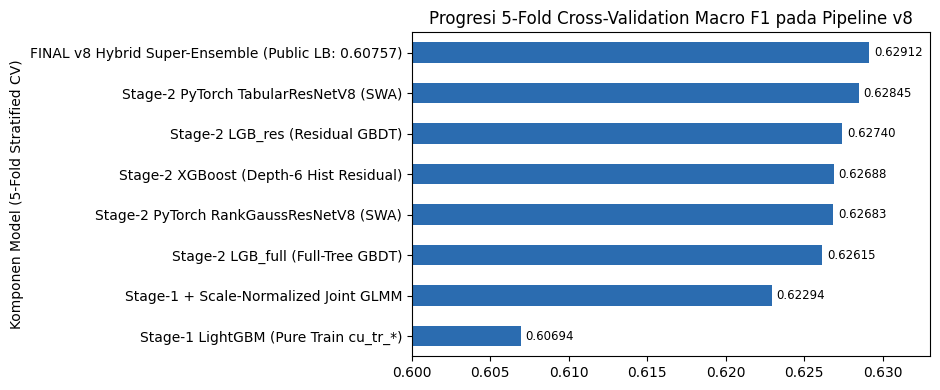

In [5]:
meta_ens = json.load(open(MODEL_OUT_DIR / "meta_v8_ensemble.json", encoding="utf-8"))
meta_s1  = json.load(open(MODEL_OUT_DIR / "meta_stage1.json", encoding="utf-8"))
meta_gl  = json.load(open(MODEL_OUT_DIR / "meta_glmm.json", encoding="utf-8"))

rows = [
    {"Komponen Model (5-Fold Stratified CV)": "Stage-1 LightGBM (Pure Train cu_tr_*)", "OOF_LogLoss": meta_s1["oof_ll"],      "CV_Macro_F1": meta_s1["cv_f1"]},
    {"Komponen Model (5-Fold Stratified CV)": "Stage-1 + Scale-Normalized Joint GLMM",  "OOF_LogLoss": meta_gl["glmm_oof_ll"], "CV_Macro_F1": meta_gl["glmm_cv_f1"]},
]
for label, fn in [
    ("Stage-2 LGB_full (Full-Tree GBDT)", "meta_lgb_full.json"),
    ("Stage-2 PyTorch RankGaussResNetV8 (SWA)", "meta_nn2.json"),
    ("Stage-2 XGBoost (Depth-6 Hist Residual)", "meta_xgb.json"),
    ("Stage-2 LGB_res (Residual GBDT)", "meta_lgb_res.json"),
    ("Stage-2 PyTorch TabularResNetV8 (SWA)", "meta_nn.json"),
]:
    d = json.load(open(MODEL_OUT_DIR / fn, encoding="utf-8"))
    rows.append({"Komponen Model (5-Fold Stratified CV)": label, "OOF_LogLoss": d["oof_ll"], "CV_Macro_F1": d["cv_f1"]})
rows.append({"Komponen Model (5-Fold Stratified CV)": "FINAL v8 Hybrid Super-Ensemble (Public LB: 0.60757)", "OOF_LogLoss": meta_ens["oof_ll"], "CV_Macro_F1": meta_ens["cv_macro_f1"]})

df_eval = pd.DataFrame(rows).round(5)
display(df_eval)

ax = df_eval.set_index("Komponen Model (5-Fold Stratified CV)")["CV_Macro_F1"].plot(kind="barh", figsize=(9.5, 4.0), color="#2b6cb0")
ax.set_xlim(0.600, 0.633)
ax.set_title("Progresi 5-Fold Cross-Validation Macro F1 pada Pipeline v8")
for idx, val in enumerate(df_eval["CV_Macro_F1"]):
    ax.text(val + 0.0003, idx, f"{val:.5f}", va="center", fontsize=8.5)
plt.tight_layout()
plt.show()
